In [1]:
#________ IMPORT ________#

#__ System __
import h5py

#__ Topophone2 __
import sys
topophone2 = "/exports/csce/datastore/geos/users/s1803569/code/2026-08_COH-INV/topophone2/topophone2"
if (topophone2 not in sys.path): sys.path.append(topophone2)
import modelling, inversion

#__ Numerical __
import numpy as np
from scipy.stats import gaussian_kde

#__ Plotting __
import matplotlib.pyplot as plt
import matplotlib.tri as tri
import matplotlib.ticker as ticker
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import cmcrameri.cm as cmc
theme = ['#DC4424', '#74A466', '#24448C', '#F8BC5C']
small, large = 8, 10
plt.rcParams["font.sans-serif"] = ['Arial']

#__ Print statement __
print("Imported modules.")

Imported modules.


In [2]:
#________ READ SIMULATION ________#

#__ Open file __
with h5py.File('abyssal_T-phase_sim.h5', 'r') as hf:

    #__ Wavefield __
    slowness_T = hf['sim_output/slowness_T'][:]   # (sensor, source, mode, direction) [s.m-1]
    energy_T   = hf['sim_output/energy_T'][:]     # (sensor, source, mode)            [uPa2.Hz-1]
    slowness_J = hf['sim_output/slowness_J'][:]   # (source, direction)               [s.m-1]
    energy_J   = hf['sim_output/energy_J'][:]     # (source)                          [uPa2.Hz-1]

    #__ Truth __
    m_true_T = hf['sim_output/m_true_T'][:]       # (sensor, parameter)
    a_true   = hf['sim_output/a'][:]              # (order)
    b_true   = hf['sim_output/b'][:]              # (order)

    #__ Geometry __
    xR = hf['geom/xR'][:]                         # (sensor, direction) [m]
    az = hf['geom/azS_J'][:]                      # (source)            [rad]
    f  = hf['geom'].attrs['f']                    # [Hz]
    s0 = hf['geom'].attrs['s0']                   # [s.m-1]

#__ Print statement __
print("Loaded simulation.")

Loaded simulation.


In [82]:
#________ SET UP INVERSIONS ________#

#__ Sensor geometries __
x_triad = xR[1:]  # Sensor position (triad) [m] (sensor, direction)
x_quad  = xR      # Sensor position (full)  [m] (sensor, direction)

#__ Frequency vector __
bw    = 1/3                                   # Frequency vector bandwidth [8ve]
nf    = 5                                     # Number of frequency bins
f_vec = f * 2.0**(np.linspace(-1,1,nf)*bw/2)  # Frequency vector [Hz] (frequency)
freq  = 2 * np.pi * f_vec                     # Frequency vector [rad.s-1] (frequency)

#__ Example data __
r_triad = x_triad[None,:,:] - x_triad[:,None,:]  # Sensor separation (triad) [m] (sensor, sensor, direction)
r_quad  = x_quad[None,:,:]  - x_quad[:,None,:]   # Sensor separation (full)  [m] (sensor, sensor, direction)
Gamma_T_triad = np.einsum(                       # Signal array covariance (triad) (frequency, sensor, sensor)
    'pq,fpqjk->fjk',
    np.nan_to_num(energy_T[0], nan=0.0),
    np.exp(1j * np.einsum('f,jkl,pql->fpqjk', freq, r_triad, np.nan_to_num(slowness_T[0], nan=0.0)))
)
Gamma_T_quad  = np.einsum(                       # Signal array covariance (full) (frequency, sensor, sensor)
    'pq,fpqjk->fjk',
    np.nan_to_num(energy_T[0], nan=0.0),
    np.exp(1j * np.einsum('f,jkl,pql->fpqjk', freq, r_quad, np.nan_to_num(slowness_T[0], nan=0.0)))
)
Gamma_J_triad = np.einsum(                       # Noise array covariance (triad) (frequency, sensor, sensor)
    'p,fpjk->fjk',
    energy_J,
    np.exp(1j * np.einsum('f,jkl,pl->fpjk', freq, r_triad, slowness_J))
)
Gamma_J_quad  = np.einsum(                       # Noise array covariance (full) (frequency, sensor, sensor)
    'p,fpjk->fjk',
    energy_J,
    np.exp(1j * np.einsum('f,jkl,pl->fpjk', freq, r_quad, slowness_J))
)
Gamma_TJ_triad = Gamma_T_triad + Gamma_J_triad  # Array covariance (full) (frequency, sensor, sensor)
Gamma_TJ_quad  = Gamma_T_quad  + Gamma_J_quad   # Array covariance (full) (frequency, sensor, sensor)

#__ Inversion parameters __
sigs = ['normal', {'sig':'noise2D', 's':s0, 'max_order':1}]
lower  = np.array([50.,  -5.0e-4, 8.0e-5, 1.0e-6, 1.0e-6, -0.99, 50., -0.8, -0.8])
upper  = np.array([100., -4.2e-4, 1.6e-4, 5.0e-5, 5.0e-5,  0.99, 100., 0.8,  0.8])
N_flow = 8
learning_rate = 5e-4
iterations    = 30000
nsample       = 100
nout          = int(iterations/5000)
N_samples     = 5000

#__ Number of observations __
Nobs_T = 16
Nobs_J = 32

#__ Truth vector for signal __
m_true = np.append(m_true_T[0], np.array([75., a_true[1], b_true[1]]))

#__ Print statement __
print("Set up inversion.")

Set up inversion.


In [83]:
#________ INVERSION HELPER ________#

#__ Helper __
def decompose(
    Gamma         : np.ndarray=None,
    Gamma_n       : np.ndarray = None,
    Nobs          : int=None,
    Nobs_n        : int        = None,
    x             : np.ndarray=None,
    freq          : np.ndarray=None,
    sigs          : list=None,
    weight_units  : str        = 'dB',
    custom_cf     : dict       = {},
    prior_bounds  : tuple=None,
    N_flow        : int=None,
    mean_field    : bool       = False,
    ini_dist      : str        = 'Uniform',
    learning_rate : float=None,
    outpath       : str        = '.',
    iterations    : int=None,
    nsample       : int=None,
    nout          : int        = 1,
    save_intermediate_result : bool = False,
    verbose       : bool       = False,
    N_samples     : int=None,
    model_outpath : str        = None,
    loss_outpath  : str        = None,
    unpack        : bool       = False,
    return_loss   : bool       = False
) -> np.ndarray:
    r'''
    `Gamma` : `numpy.ndarray`
        Observed array-covariance matrix
        (frequency, sensor, sensor)

    `Gamma_n` : `numpy.ndarray`
        Observed noise-only array-covariance matrix
        (frequency, sensor, sensor)

    `Nobs` : `int`
        Degrees of freedom

    `Nobs_n` : `int`
        Degrees of freedom (noise)

    `x` : `numpy.ndarray`
        Sensor position [m]
        (sensor, direction)

    `freq` : `numpy.ndarray`
        Angular frequency vector [rad.s-1]
        (frequency)

    `sigs` : `list`
        List of signals

    `weight_units` : `str`
        Units of the signal weights in the model vector
        ('dB' or 'linear')

    `custom_cf` : `dict`
        Custom characteristic functions keyed by signal name

    `prior_bounds` : `(numpy.ndarray,numpy.ndarray)`
        Prior bounds

    `N_flow` : `int`
        Number of normalising flows

    `mean_field` : `bool`
        Use mean-field approximation

    `ini_dist` : `str`
        Initial distribution to transform

    `learning_rate` : `float`

    `outpath` : `str`


    '''

    #__ Set up array-covariance model __
    if (Gamma_n is not None) : calc_noise_only = True
    else:                      calc_noise_only = False
    model = modelling.ArrayCovarianceModel(
        x               = x,
        freq            = freq,
        signal_types    = sigs,
        weight_units    = weight_units,
        calc_noise_only = calc_noise_only,
        custom_cf       = custom_cf
    )

    #__ Set up prior pdf __
    prior = inversion.Uniform(*prior_bounds)

    #__ Set up posterior pdf __
    posterior = inversion.Posterior(
        Gamma_obs             = Gamma,
        N_obs                 = Nobs,
        arraycovariance_model = model,
        prior                 = prior,
        Gamma_obs_noise       = Gamma_n,
        N_obs_noise           = Nobs_n
    )

    #__ Set up normalising flow model __
    flow = inversion.LinearFlowsModel(
        N_param      = len(prior_bounds[0]),
        prior_bounds = prior_bounds,
        N_flow       = N_flow,
        mean_field   = mean_field,
        ini_dist     = ini_dist
    )

    #__ Set up inverse problem __
    inverse = inversion.VI(
        flow_model    = flow,
        posterior     = posterior,
        learning_rate = learning_rate,
        outpath       = outpath
    )

    #__ Perform inversion __
    inverse.invert(
        iterations = iterations,
        nsample    = nsample,
        nout       = nout,
        save_intermediate_result = save_intermediate_result,
        verbose    = verbose
    )
    loss = inverse.loss_his

    #__ Sample posterior __
    m = inverse.sample(N_samples=N_samples)

    #__ Save models __
    if model_outpath: np.savetxt(model_outpath, m)
    if loss_outpath : np.savetxt(loss_outpath,  loss)

    #__ Unpack __
    if unpack: m = inverse.unpack(m)

    #__ Return output __
    if return_loss: return m, loss
    else:           return m, posterior

#__ Print statement __
print("Defined inversion helper function.")

Defined inversion helper function.


----------------------------------------

Iteration:     0,	Loss:   51356.15
The elapsed time is: 0.01 s
Iteration:  5000,	Loss:   13909.48
The elapsed time is: 60.31 s
Iteration: 10000,	Loss:   13851.87
The elapsed time is: 119.23 s
Iteration: 15000,	Loss:   13849.36
The elapsed time is: 178.13 s
Iteration: 20000,	Loss:   13849.40
The elapsed time is: 237.42 s
Iteration: 25000,	Loss:   13849.34
The elapsed time is: 296.32 s
Iteration: 30000,	Loss:   13849.42
The elapsed time is: 355.53 s
----------------------------------------

Finish training!


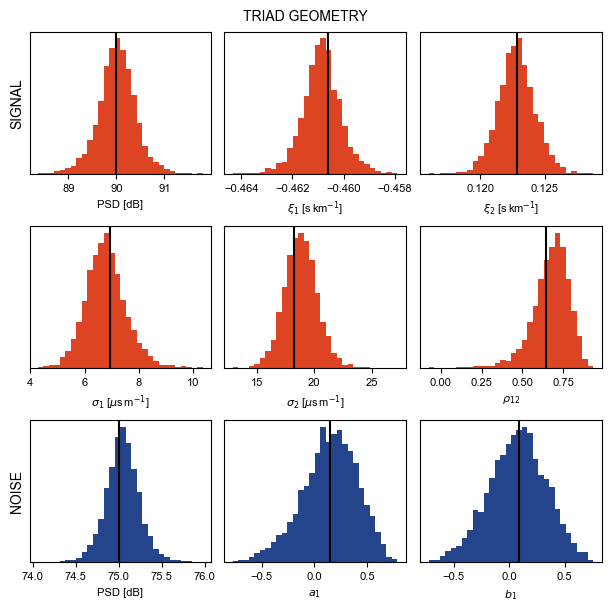

In [84]:
#________ PERFORM TRIAD INVERSION ________#

#__ Triad inversion __
m_triad, post_triad = decompose(
    Gamma   = Gamma_TJ_triad,
    Nobs    = Nobs_T,
    Gamma_n = Gamma_J_triad,
    Nobs_n  = Nobs_J,
    x       = x_triad,
    freq    = freq,
    sigs    = sigs,
    prior_bounds  = (lower,upper),
    N_flow        = N_flow,
    learning_rate = learning_rate,
    iterations    = iterations,
    nsample       = nsample,
    nout          = nout,
    verbose = True,
    N_samples     = N_samples
)

#________ PLOT HISTOGRAMS ________#

#__ Create figure and axes __
fig, axs = plt.subplots(
    nrows=3, ncols=3,
    figsize=(6,6), facecolor='white', layout='constrained'
)

#__ Set labels and scales __
labels = [
    r"PSD [dB]", r"$\xi_1$ [s$\,$km$^{-1}$]", r"$\xi_2$ [s$\,$km$^{-1}$]",
    r"$\sigma_1$ [$\mu$s$\,$m$^{-1}$]", r"$\sigma_2$ [$\mu$s$\,$m$^{-1}$]", r"$\rho_{12}$",
    r"PSD [dB]", r"$a_1$", r"$b_1$"
]
scales = [
    1e0, 1e3, 1e3,
    1e6, 1e6, 1e0,
    1e0, 1e0, 1e0
]

#__ Format __
fig.suptitle('TRIAD GEOMETRY', fontsize=large)
axs[0,0].set_ylabel('SIGNAL', fontsize=large)
axs[2,0].set_ylabel('NOISE',  fontsize=large)
for ax, lab in zip(axs.flatten(), labels):
    ax.set_xlabel(lab, fontsize=small)
    ax.set_yticks([])
    ax.tick_params(labelsize=small)

#__ Plot histograms __
for i, (ax, sc) in enumerate(zip(axs.flatten(), scales)):
    if (i < 6): c = theme[0]
    else:       c = theme[2]
    ax.hist(sc*m_triad[:,i], bins=30, color=c, zorder=1)
    ax.axvline(sc*m_true[i], color='k', zorder=2)

#__ Show figure __
fig.show()

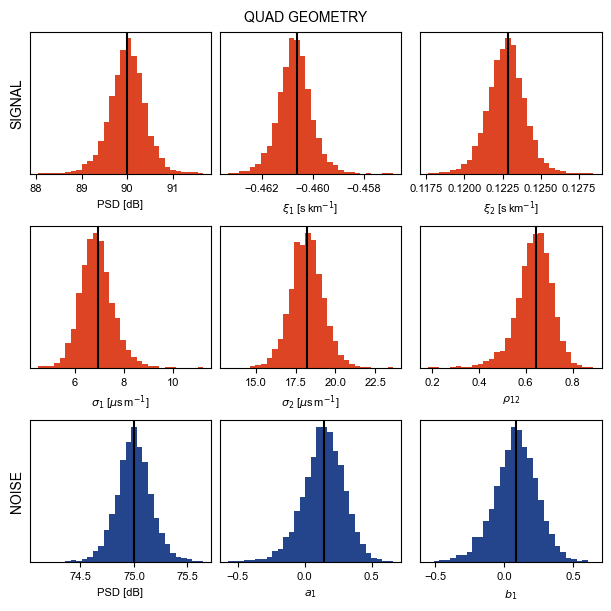

In [27]:
#________ PERFORM FULL INVERSION ________#

#__ Full inversion __
m_quad = decompose(
    Gamma   = Gamma_TJ_quad,
    Nobs    = Nobs_T,
    Gamma_n = Gamma_J_quad,
    Nobs_n  = Nobs_J,
    x       = x_quad,
    freq    = freq,
    sigs    = sigs,
    prior_bounds  = (lower,upper),
    N_flow        = N_flow,
    learning_rate = learning_rate,
    iterations    = iterations,
    nsample       = nsample,
    nout          = nout,
    verbose = True,
    N_samples     = N_samples
)

#________ PLOT HISTOGRAMS ________#

#__ Create figure and axes __
fig, axs = plt.subplots(
    nrows=3, ncols=3,
    figsize=(6,6), facecolor='white', layout='constrained'
)

#__ Set labels and scales __
labels = [
    r"PSD [dB]", r"$\xi_1$ [s$\,$km$^{-1}$]", r"$\xi_2$ [s$\,$km$^{-1}$]",
    r"$\sigma_1$ [$\mu$s$\,$m$^{-1}$]", r"$\sigma_2$ [$\mu$s$\,$m$^{-1}$]", r"$\rho_{12}$",
    r"PSD [dB]", r"$a_1$", r"$b_1$"
]
scales = [
    1e0, 1e3, 1e3,
    1e6, 1e6, 1e0,
    1e0, 1e0, 1e0
]

#__ Format __
fig.suptitle('QUAD GEOMETRY', fontsize=large)
axs[0,0].set_ylabel('SIGNAL', fontsize=large)
axs[2,0].set_ylabel('NOISE',  fontsize=large)
for ax, lab in zip(axs.flatten(), labels):
    ax.set_xlabel(lab, fontsize=small)
    ax.set_yticks([])
    ax.tick_params(labelsize=small)

#__ Plot histograms __
for i, (ax, sc) in enumerate(zip(axs.flatten(), scales)):
    if (i < 6): c = theme[0]
    else:       c = theme[2]
    ax.hist(sc*m_quad[:,i], bins=30, color=c, zorder=1)
    ax.axvline(sc*m_true[i], color='k', zorder=2)

#__ Show figure __
fig.show()

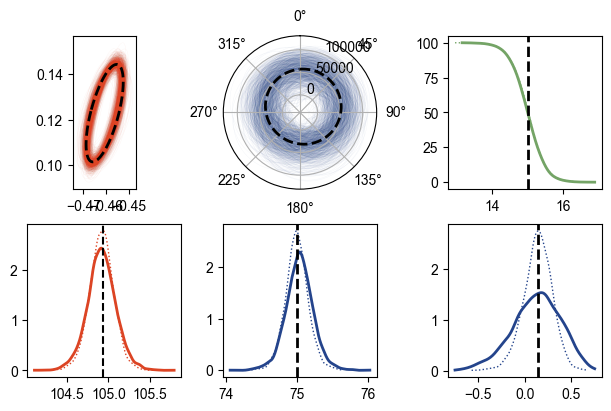

In [62]:
#________ PLOT ________#

#__ Helpers __
def mahalanobis_ellipse(mean, C, q=2*np.log(2), n=400):
    """Ellipse where (s-mean)^T C^-1 (s-mean) = q."""
    vals, vecs = np.linalg.eigh(C)
    t   = np.linspace(0, 2*np.pi, n)
    pts = np.column_stack([np.cos(t), np.sin(t)]) * np.sqrt(q) * np.sqrt(vals)[None,:]
    return np.asarray(mean)[None,:] + pts @ vecs.T
def cov_from_params(sig_x, sig_y, rho):
    return np.array([[sig_x**2,        rho*sig_x*sig_y],
                     [rho*sig_x*sig_y, sig_y**2       ]])
def kde_1d(samples, n_points=500, bw_method=None, bounds=None):
    samples = np.asarray(samples).ravel()
    kde = gaussian_kde(samples, bw_method=bw_method)
    lo, hi = bounds if bounds is not None else (samples.min(), samples.max())
    x = np.linspace(lo, hi, n_points)
    density = kde(x)
    return x, density, kde
order2D = np.arange(len(a_true))
cos_2D  = np.cos(order2D[None,:] * az[:,None])
sin_2D  = np.sin(order2D[None,:] * az[:,None])
e_m     = np.ones(len(order2D)); e_m[1:] = 2.0
xi_true = m_true_T[1:3]
C_true  = cov_from_params(*m_true[3:6])

#__ Create figure and axes __
fig = plt.figure(figsize=(6,4), facecolor='white', layout='constrained')
axs = [
    fig.add_subplot(2,3,1, aspect='equal'),
    fig.add_subplot(2,3,2, projection='polar'),
    fig.add_subplot(2,3,3),
    fig.add_subplot(2,3,4),
    fig.add_subplot(2,3,5),
    fig.add_subplot(2,3,6)
]
axs[0].set_aspect('equal')
axs[1].set_theta_zero_location('N')
axs[1].set_theta_direction(-1)

#__ Plot signal-to-noise estimate __
x_snr, _, kde_snr = kde_1d(m_triad[:,0]-m_triad[:,6])
sf_snr = np.array([kde_snr.integrate_box_1d(xi, np.inf) for xi in x_snr])
p5_snr, p95_snr = np.percentile(m_triad[:,0]-m_triad[:,6], [5,95])
axs[2].plot(x_snr, 100*sf_snr, lw=2.0, c=theme[1], zorder=1)
# axs[0].axvline(p5_snr, lw=1.0, color=theme[3], zorder=2)
# axs[0].axvline(p95_snr, lw=1.0, color=theme[3], zorder=2)
axs[2].axvline(m_true[0]-m_true[6], color='k', lw=2.0, ls='--', zorder=3)

#__ Plot signal-to-noise estimate with extra sensor __
x_snr, _, kde_snr = kde_1d(m_quad[:,0]-m_quad[:,6])
sf_snr = np.array([kde_snr.integrate_box_1d(xi, np.inf) for xi in x_snr])
axs[2].plot(x_snr, 100*sf_snr, lw=1.0, c=theme[1], ls=':', zorder=1)

#__ Plot signal estimates __
for j in range(1000):
    E = mahalanobis_ellipse(m_triad[j,1:3], cov_from_params(*m_triad[j,3:6]))
    axs[0].plot(1e3*E[:,0], 1e3*E[:,1], c=theme[0], lw=0.3, alpha=0.05, zorder=1)
E_true = mahalanobis_ellipse(m_true[1:3], cov_from_params(*m_true[3:6]))
axs[0].plot(1e3*E_true[:,0], 1e3*E_true[:,1], c='k', ls='--', lw=2.0, zorder=3)

#__ Plot noise estimates __
J_dB_hat, a1_hat, b1_hat = m_triad[:,6], m_triad[:,7], m_triad[:,8]
J_Pa_hat = 10 ** (J_dB_hat/10)
a_hat = np.column_stack([np.ones_like(a1_hat), a1_hat])
b_hat = np.column_stack([np.zeros_like(b1_hat), b1_hat])
energy_J_hat  = np.sum(e_m[None,None,:] * (a_hat[:,None,:]*cos_2D[None,:,:]
                                           + b_hat[:,None,:]*sin_2D[None,:,:]), axis=2)
energy_J_hat *= J_Pa_hat[:,None] / np.nansum(energy_J_hat, axis=1, keepdims=True)
for j in range(1000):
    axs[1].plot(az, energy_J_hat[j], lw=0.3, alpha=0.05, color=theme[2], zorder=1)
axs[1].plot(az, energy_J, lw=2.0, color='k', ls='--', zorder=2)
# axs[2].scatter(0, 0, marker='^', c=theme[1], s=30, zorder=3)

#__ Plot backazimuth estimates __
x_baz, density_baz, _ = kde_1d((np.rad2deg(np.arctan2(m_triad[:,1],m_triad[:,2])) + 180)%360)
axs[3].plot(x_baz, density_baz, lw=2.0, color=theme[0], zorder=1)
axs[3].axvline((np.rad2deg(np.arctan2(m_true[1],m_true[2])) + 180)%360, color='k', ls='--', zorder=2)

#__ Plot noise coefficient estimates __
x_a, density_a, _ = kde_1d(m_triad[:,6])
x_b, density_b, _ = kde_1d(m_triad[:,7])
axs[4].plot(x_a, density_a, color=theme[2], lw=2.0, zorder=1)
axs[5].plot(x_b, density_b, color=theme[2], lw=2.0, zorder=1)
axs[4].axvline(m_true[6], color='k', lw=2.0, ls='--', zorder=2)
axs[5].axvline(m_true[7], color='k', lw=2.0, ls='--', zorder=2)

#__ Plot estimates with extra sensor __
x_baz, density_baz, _ = kde_1d((np.rad2deg(np.arctan2(m_quad[:,1],m_quad[:,2])) + 180)%360)
x_a, density_a, _ = kde_1d(m_quad[:,6])
x_b, density_b, _ = kde_1d(m_quad[:,7])
axs[3].plot(x_baz, density_baz, lw=1.0, color=theme[0], ls=':',zorder=1)
axs[4].plot(x_a, density_a, color=theme[2], ls=':', lw=1.0, zorder=1)
axs[5].plot(x_b, density_b, color=theme[2], ls=':', lw=1.0, zorder=1)

#__ Show figure __
fig.show()

In [85]:
#________ CREATE CUSTOM FUNCTION ________#

#__ Apparent velocity beamwidth only __
def cf_radial2D(
    t : np.ndarray,
    mi : np.ndarray
):
    r"""

    log(cf) = i (t.xi) - (1/2) sigma^2 (t.xi)^2 / (xi.xi)

    Input
    -----
    `t` : `numpy.ndarray`
        Characteristic function argument, omega * R
        (frequency, sensor pair, direction)

    `mi` : `numpy.ndarray`
        Model with mean slowness (X,Y) and radial beamwidth parameters
        (model, parameter)

    Output
    ------
    `cf` : `numpy.ndarray`
        Characteristic function
        (model, frequency, sensor pair)

    `dcf` : `numpy.ndarray`
        Gradient of characteristic function
        (model, frequency, sensor pair, parameter)
    """

    #__ np.einsum subscripts:
    #__ [i] model
    #__ [j] frequency
    #__ [k] sensor pair
    #__ [l],[p] direction

    #__ Unpack model vector __
    xi    = mi[:, :2]  # (i,l)
    sigma = mi[:, 2]   # (i,)

    #__ Invariants __
    u  = np.einsum('jkl,il->ijk', t, xi, optimize=True)  # (i,j,k)  t.xi
    s  = np.einsum('il,il->i', xi, xi, optimize=True)    # (i,)     xi.xi
    s3 = s[:, None, None]                                # (i,1,1)
    g  = u / s3                                          # (i,j,k)
    v2 = (sigma**2)[:, None, None]                       # (i,1,1)

    #__ Calculate characteristic function __
    L  = 1j * u
    Q  = -0.5 * v2 * u * g
    cf = np.exp(L + Q)

    #__ Calculate gradients __
    #__ d/dxi  = i t - sigma^2 (u/s) [ t - (u/s) xi ]
    #__ d/dsig = -sigma u^2 / s
    t_perp = t[None, ...] - g[..., None] * xi[:, None, None, :]     # (i,j,k,l)
    dlog          = np.empty(cf.shape + (mi.shape[1],), dtype=cf.dtype)
    dlog[...]     = 0.0
    dlog[..., :2] = 1j * t[None, ...] - (v2 * g)[..., None] * t_perp
    dlog[..., 2]  = -sigma[:, None, None] * u * g
    dcf           = cf[..., None] * dlog

    #__ Return output __
    return cf, dcf

#__ Set up inversion again __
sigs_rad = ['radial2D', {'sig':'noise2D', 's':s0, 'max_order':1}]
lower_rad  = np.array([50.,  -5.0e-4, 8.0e-5, 1.0e-6, 50., -0.8, -0.8])
upper_rad  = np.array([100., -4.2e-4, 1.6e-4, 5.0e-5, 100., 0.8,  0.8])

#__ Inversion __
m_rad, post_rad = decompose(
    Gamma   = Gamma_TJ_triad,
    Nobs    = Nobs_T,
    Gamma_n = Gamma_J_triad,
    Nobs_n  = Nobs_J,
    x       = x_triad,
    freq    = freq,
    sigs    = sigs_rad,
    custom_cf = {'radial2D':(3,cf_radial2D)},
    prior_bounds  = (lower_rad,upper_rad),
    N_flow        = N_flow,
    learning_rate = learning_rate,
    iterations    = iterations,
    nsample       = nsample,
    nout          = nout,
    verbose = True,
    N_samples     = N_samples
)

----------------------------------------

Iteration:     0,	Loss:   73685.25
The elapsed time is: 0.19 s
Iteration:  5000,	Loss:   14506.58
The elapsed time is: 58.45 s
Iteration: 10000,	Loss:   14306.05
The elapsed time is: 117.78 s
Iteration: 15000,	Loss:   14300.88
The elapsed time is: 176.85 s
Iteration: 20000,	Loss:   14301.01
The elapsed time is: 234.78 s
Iteration: 25000,	Loss:   14301.01
The elapsed time is: 293.18 s
Iteration: 30000,	Loss:   14301.12
The elapsed time is: 351.44 s
----------------------------------------

Finish training!


In [15]:
#________ COMPUTE EVIDENCE ________#

import harmonic as hm
import numpy as np

#__ Helper function __
def calc_evidence(m, lnL, lnV, nchains=10, temperature=0.8):
    
    #__ Reshape __
    ndim = m.shape[-1]
    m = m.reshape(nchains, -1, ndim)
    lnprob = (lnL - lnV).reshape(nchains, -1)

    chains = hm.Chains(ndim)
    chains.add_chains_3d(m, lnprob)
    chains_train, chains_infer = hm.utils.split_data(chains, training_proportion=0.5)

    model = hm.model.RQSplineModel(ndim, standardize=True, temperature=temperature)
    model.fit(chains_train.samples)

    ev = hm.Evidence(chains_infer.nchains, model)
    ev.add_chains(chains_infer)

    ln_Z, _ = ev.compute_ln_evidence()
    err_lo, err_hi = ev.compute_ln_inv_evidence_errors()
    return ln_Z, (err_lo, err_hi)

#__ Load pre-calculated arrays __
arrs = np.load('./evidence_calc.npz')
m_triad = arrs['m_triad']
m_rad = arrs['m_rad']
lnL_triad = arrs['lnL_triad']
lnL_rad = arrs['lnL_rad']
lnV_triad = arrs['lnV_triad']
lnV_rad = arrs['lnV_rad']

# #__ Calculate likelihood __
# lnL_triad, _ = post_triad.log_likelihood(m_triad, grad=False)
# lnL_rad, _   = post_rad.log_likelihood(  m_rad, grad=False)

# #__ Calculate prior volume __
# lnV_triad = np.sum(np.log(upper-lower))
# lnV_rad   = np.sum(np.log(upper_rad-lower_rad))

#__ Calculate the evidence __
ln_Z_triad, err_triad = calc_evidence(m_triad, lnL_triad, lnV_triad)
ln_Z_rad, err_rad   = calc_evidence(m_rad,   lnL_rad,   lnV_rad)

In [22]:
bf_nats = ln_Z_triad - ln_Z_rad

bf_bits = bf_nats / np.log(2)

In [23]:
bf_bits

np.float64(651.3739931976153)

In [19]:
d_lnL_max = lnL_triad.max() - lnL_rad.max()
occam     = ln_bf - d_lnL_max

In [20]:
d_lnL_max, occam

(np.float64(456.2997546852712), np.float64(-4.801707810271182))

In [16]:
ln_bf = ln_Z_triad - ln_Z_rad
ln_bf_err = np.hypot(err_triad, err_rad)

In [17]:
ln_bf, ln_bf_err

(np.float32(451.49805), array([0.07686393, 0.07153053], dtype=float32))

In [13]:
bayes_factor = np.exp(ev_triad - ev_rad)

/tmp/ipykernel_1767011/2318372471.py:1: RuntimeWarning: overflow encountered in exp
  bayes_factor = np.exp(ev_triad - ev_rad)


In [14]:
ev_triad - ev_rad

np.float32(451.49805)

In [11]:
ev_triad, stdev_triad

(np.float32(-13849.52), (np.float32(-0.07604133), np.float32(0.070665486)))

In [10]:
ev_rad

np.float32(-14301.018)

In [4]:
m_triad.shape

(5000, 9)

In [5]:
lnL_triad.shape

(5000,)

In [94]:
np.savez_compressed('./evidence_calc', m_triad=m_triad, m_rad=m_rad, lnL_triad=lnL_triad, lnL_rad=lnL_rad, lnV_triad=lnV_triad, lnV_rad=lnV_rad)

In [79]:
#__ Calculate likelihoods __
lnL_rad, _ = post_rad.log_likelihood(m_rad, grad=False)

In [80]:
lnL_rad

array([-14283.55465109, -14285.25065816, -14282.9453737 , ...,
       -14283.84426632, -14283.77122338, -14282.63262378])

(array([2.000e+00, 3.000e+00, 2.100e+01, 1.820e+02, 9.470e+02, 2.078e+03,
        1.402e+03, 3.160e+02, 4.400e+01, 5.000e+00]),
 array([85.96077825, 86.48645906, 87.01213987, 87.53782067, 88.06350148,
        88.58918228, 89.11486309, 89.64054389, 90.1662247 , 90.69190551,
        91.21758631]),
 <BarContainer object of 10 artists>)

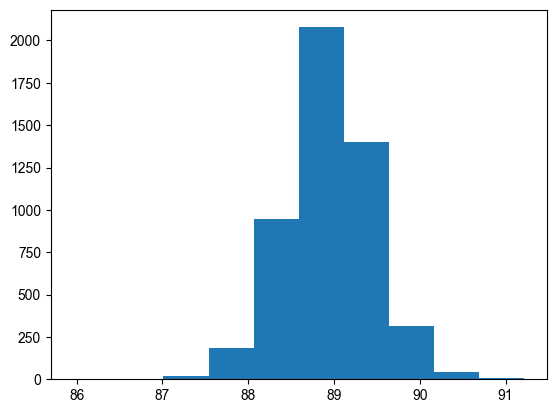

In [73]:
plt.hist(m_rad[:,0])

(array([   5.,   14.,   72.,  404., 1394., 1935.,  908.,  213.,   45.,
          10.]),
 array([-0.00046434, -0.00046366, -0.00046299, -0.00046232, -0.00046165,
        -0.00046097, -0.0004603 , -0.00045963, -0.00045896, -0.00045828,
        -0.00045761]),
 <BarContainer object of 10 artists>)

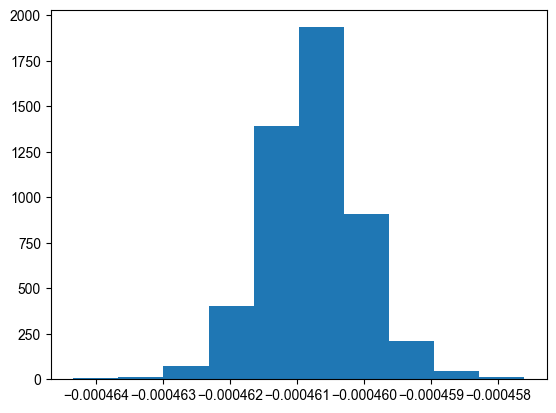

In [74]:
plt.hist(m_rad[:,1])

(array([1.000e+00, 1.300e+01, 6.900e+01, 4.890e+02, 1.871e+03, 1.935e+03,
        5.330e+02, 7.900e+01, 6.000e+00, 4.000e+00]),
 array([0.00011856, 0.00011944, 0.00012032, 0.0001212 , 0.00012208,
        0.00012297, 0.00012385, 0.00012473, 0.00012561, 0.00012649,
        0.00012738]),
 <BarContainer object of 10 artists>)

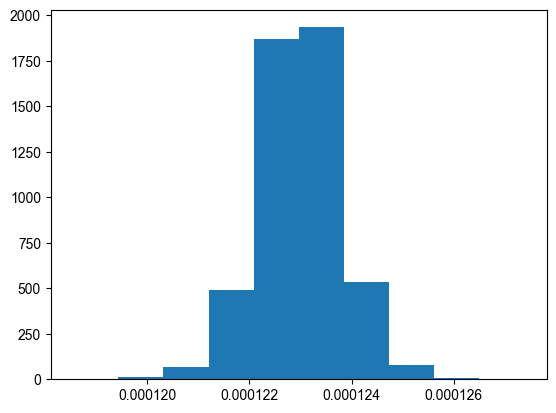

In [75]:
plt.hist(m_rad[:,2])

(array([  3.,  23.,  49., 105., 164., 246., 333., 339., 463., 417., 392.,
        378., 361., 311., 275., 211., 158., 134., 113.,  85.,  78.,  62.,
         43.,  34.,  26.,  31.,  15.,  15.,  21.,  17.,  14.,   4.,   9.,
          8.,   9.,   7.,   5.,   6.,   3.,   3.,   1.,   7.,   1.,   3.,
          1.,   1.,   3.,   2.,   1.,   0.,   3.,   0.,   1.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   1.,   1.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   1.,   0.,   0.,   0.,   1.,   0.,   0.,
          0.,   1.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          1.]),
 array([1.15638565e-06, 1.30625515e-06, 1.45612465e-06, 1.60599415e-06,
        1.75586364e-06, 1.90573314e-06, 2.05560264e-06, 2.20547214e-06,
        2.35534164e-06, 2.50521114e-06, 2.65508063e-06, 2.80495013e-06,
        2.95481963e-06, 3.10468913e-06, 3.25455863e-06, 3.40442813e-06,
        3.55429763e-06, 3.7041

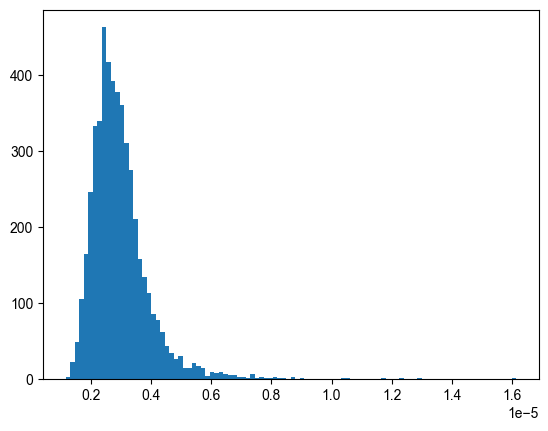

In [76]:
plt.hist(m_rad[:,3], bins=100)

In [ ]:
#__ Apparent velocity beamwidth only __
def cf_radial_2D(
    t : np.ndarray,
    mi : np.ndarray,
    i_sigma : int = 2,
    eps : float = 1e-300
):
    r"""
    Characteristic function of a rank-one Gaussian slowness distribution
    whose only non-null direction is radial (parallel to the mean
    slowness), i.e. zero backazimuth beamwidth.

        log(cf) = i (t.xi) - (1/2) sigma^2 (t.xi)^2 / (xi.xi)

    Input
    -----
    `t` : `numpy.ndarray`
        Characteristic function argument, omega * R
        (frequency, sensor pair, direction)

    `mi` : `numpy.ndarray`
        Model with mean slowness (X,Y) and radial beamwidth parameters
        (model, parameter)

    `i_sigma` : `int`
        Column of `mi` holding the radial beamwidth.

    Output
    ------
    `cf` : `numpy.ndarray`
        (model, frequency, sensor pair), complex

    `dcf` : `numpy.ndarray`
        Gradient of `cf` wrt (xi_X, xi_Y, sigma)
        (model, frequency, sensor pair, parameter), complex
    """

    #__ np.einsum subscripts:
    #__ [i] model
    #__ [j] frequency
    #__ [k] sensor pair
    #__ [l],[p] direction

    #__ Unpack model vector __
    xi    = mi[:, :2]                                   # (i,l)
    sigma = mi[:, i_sigma]                              # (i,)

    #__ Invariants __
    u = np.einsum('jkl,il->ijk', t, xi, optimize=True)  # (i,j,k)  t.xi
    s = np.einsum('il,il->i', xi, xi, optimize=True)    # (i,)     xi.xi
    s = np.maximum(s, eps)                              # radial axis undefined at xi = 0

    s3 = s[:, None, None]                               # (i,1,1)
    g  = u / s3                                         # (i,j,k)  u/s
    v2 = (sigma**2)[:, None, None]                      # (i,1,1)

    #__ Calculate characteristic function __
    L  = 1j * u
    Q  = -0.5 * v2 * u * g
    cf = np.exp(L + Q)

    #__ Calculate gradients __
    #__ d/dxi  = i t - sigma^2 (u/s) [ t - (u/s) xi ]
    #__ d/dsig = -sigma u^2 / s
    t_perp = t[None, ...] - g[..., None] * xi[:, None, None, :]     # (i,j,k,l)

    dlog          = np.empty(cf.shape + (mi.shape[1],), dtype=cf.dtype)
    dlog[...]     = 0.0
    dlog[..., :2] = 1j * t[None, ...] - (v2 * g)[..., None] * t_perp
    dlog[..., i_sigma] = -sigma[:, None, None] * u * g

    dcf = cf[..., None] * dlog

    return cf, dcf

In [35]:
x_snr, density_snr, kde_snr = kde_1d(m_triad[:,0]-m_triad[:,6])

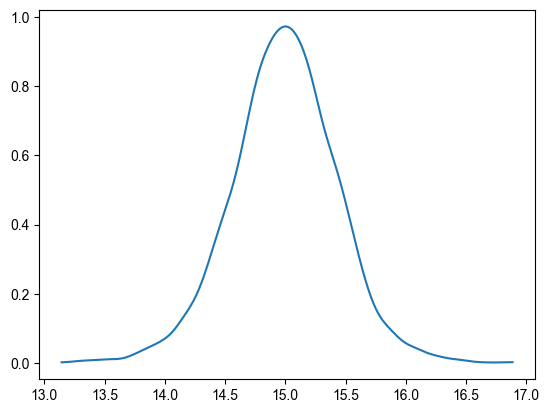

In [36]:
plt.plot(x_snr, density_snr)

In [42]:
sf_snr = np.array([kde_snr.integrate_box_1d(xi, np.inf) for xi in x_snr])

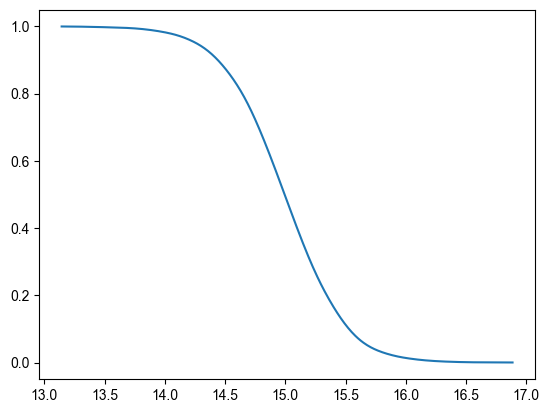

In [43]:
plt.plot(x_snr, sf_snr)

In [3]:
#________ BUILD ARRAY COVARIANCE ________#

#__ Array geometry __
x     = xR[1:]                                      # Sensor position [m]         (sensor, direction)
bw    = 2/3
nf    = 3
f_vec = f * 2.0**(np.linspace(-1,1,nf)*bw/2)        # Frequency [Hz]              (frequency)
freq  = 2*np.pi*f_vec                               # Angular frequency [rad.s-1] (frequency)
r     = x[None,:,:] - x[:,None,:]                   # Sensor separation [m]       (sensor, sensor, direction)

#__ Signal __
Gamma_T = np.einsum(              # Signal array covariance (frequency, sensor, sensor)
    'pq,fpqjk->fjk',
    np.nan_to_num(energy_T[0], nan=0.0),
    np.exp(1j * np.einsum('f,jkl,pql->fpqjk', freq, r, np.nan_to_num(slowness_T[0], nan=0.0)))
)

#__ Noise __
Gamma_J = np.einsum(              # Noise array covariance (frequency, sensor, sensor)
    'p,fpjk->fjk',
    energy_J,
    np.exp(1j * np.einsum('f,jkl,pl->fpjk', freq, r, slowness_J))
)

#__ Combined __
Gamma_TJ = Gamma_T + Gamma_J

#__ Number of observations __
Nobs_T = 16
Nobs_J = 32

#__ Truth vector for signal __
m_true = m_true_T[0]

In [10]:
#________ INVERSION HELPER ________#

#__ Helper __
def decompose(
    Gamma         : np.ndarray=None,
    Gamma_n       : np.ndarray = None,
    Nobs          : int=None,
    Nobs_n        : int        = None,
    x             : np.ndarray=None,
    freq          : np.ndarray=None,
    sigs          : list=None,
    weight_units  : str        = 'dB',
    custom_cf     : dict       = {},
    prior_bounds  : tuple=None,
    N_flow        : int=None,
    mean_field    : bool       = False,
    ini_dist      : str        = 'Uniform',
    learning_rate : float=None,
    outpath       : str        = '.',
    iterations    : int=None,
    nsample       : int=None,
    nout          : int        = 1,
    save_intermediate_result : bool = False,
    verbose       : bool       = False,
    N_samples     : int=None,
    model_outpath : str        = None,
    loss_outpath  : str        = None,
    unpack        : bool       = False,
    return_loss   : bool       = False
) -> np.ndarray:
    r'''
    `Gamma` : `numpy.ndarray`
        Observed array-covariance matrix
        (frequency, sensor, sensor)

    `Gamma_n` : `numpy.ndarray`
        Observed noise-only array-covariance matrix
        (frequency, sensor, sensor)

    `Nobs` : `int`
        Degrees of freedom

    `Nobs_n` : `int`
        Degrees of freedom (noise)

    `x` : `numpy.ndarray`
        Sensor position [m]
        (sensor, direction)

    `freq` : `numpy.ndarray`
        Angular frequency vector [rad.s-1]
        (frequency)

    `sigs` : `list`
        List of signals

    `weight_units` : `str`
        Units of the signal weights in the model vector
        ('dB' or 'linear')

    `custom_cf` : `dict`
        Custom characteristic functions keyed by signal name

    `prior_bounds` : `(numpy.ndarray,numpy.ndarray)`
        Prior bounds

    `N_flow` : `int`
        Number of normalising flows

    `mean_field` : `bool`
        Use mean-field approximation

    `ini_dist` : `str`
        Initial distribution to transform

    `learning_rate` : `float`

    `outpath` : `str`


    '''

    #__ Set up array-covariance model __
    if Gamma_n : calc_noise_only = True
    else:        calc_noise_only = False
    model = modelling.ArrayCovarianceModel(
        x               = x,
        freq            = freq,
        signal_types    = sigs,
        weight_units    = weight_units,
        calc_noise_only = calc_noise_only,
        custom_cf       = custom_cf
    )

    #__ Set up prior pdf __
    prior = inversion.Uniform(*prior_bounds)

    #__ Set up posterior pdf __
    posterior = inversion.Posterior(
        Gamma_obs             = Gamma,
        N_obs                 = Nobs,
        arraycovariance_model = model,
        prior                 = prior,
        Gamma_obs_noise       = Gamma_n,
        N_obs_noise           = Nobs_n
    )

    #__ Set up normalising flow model __
    flow = inversion.LinearFlowsModel(
        N_param      = len(prior_bounds[0]),
        prior_bounds = prior_bounds,
        N_flow       = N_flow,
        mean_field   = mean_field,
        ini_dist     = ini_dist
    )

    #__ Set up inverse problem __
    inverse = inversion.VI(
        flow_model    = flow,
        posterior     = posterior,
        learning_rate = learning_rate,
        outpath       = outpath
    )

    #__ Perform inversion __
    inverse.invert(
        iterations = iterations,
        nsample    = nsample,
        nout       = nout,
        save_intermediate_result = save_intermediate_result,
        verbose    = verbose
    )
    loss = inverse.loss_his

    #__ Sample posterior __
    m = inverse.sample(N_samples=N_samples)

    #__ Save models __
    if model_outpath: np.savetxt(model_outpath, m)
    if loss_outpath : np.savetxt(loss_outpath,  loss)

    #__ Unpack __
    if unpack: m = inverse.unpack(m)

    #__ Return output __
    if return_loss: return m, loss
    else:           return m

----------------------------------------

Iteration:     0,	Loss:  710450.02
The elapsed time is: 0.01 s
Iteration:  5000,	Loss:    3544.13
The elapsed time is: 31.45 s
Iteration: 10000,	Loss:    3152.83
The elapsed time is: 69.20 s
Iteration: 15000,	Loss:    3115.25
The elapsed time is: 104.42 s
Iteration: 20000,	Loss:    3034.76
The elapsed time is: 137.24 s
Iteration: 25000,	Loss:    3033.99
The elapsed time is: 170.00 s
Iteration: 30000,	Loss:    3034.18
The elapsed time is: 202.86 s
Iteration: 35000,	Loss:    3034.26
The elapsed time is: 236.32 s
Iteration: 40000,	Loss:    3034.11
The elapsed time is: 270.37 s
Iteration: 45000,	Loss:    3034.13
The elapsed time is: 305.58 s
Iteration: 50000,	Loss:    3034.16
The elapsed time is: 340.13 s
----------------------------------------

Finish training!


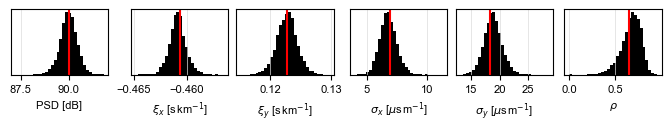

In [46]:
#________ TEST ________#

#__ Set up __
sigs   = ['normal']
lower  = np.array([50.,  -5.7e-4, 2.3e-5, 1.0e-6, 1.0e-6, -0.99])
upper  = np.array([100., -3.6e-4, 2.3e-4, 5.0e-5, 5.0e-5,  0.99])
N_flow = 8
learning_rate = 5e-4
iterations = 50000
nsample    = 100
nout       = int(iterations/5000)
N_samples  = 5000

#__ Data __
bw    = 1/4
nf    = 5
f_vec = f * 2.0**(np.linspace(-1,1,nf)*bw/2)        # Frequency [Hz]              (frequency)
Gamma_T = np.einsum(              # Signal array covariance (frequency, sensor, sensor)
    'pq,fpqjk->fjk',
    np.nan_to_num(energy_T[0], nan=0.0),
    np.exp(1j * np.einsum('f,jkl,pql->fpqjk', freq, r, np.nan_to_num(slowness_T[0], nan=0.0)))
)

#__ Inversion __
m = decompose(
    Gamma = Gamma_T,
    Nobs  = Nobs_T,
    x     = x,
    freq  = freq,
    sigs  = sigs,
    prior_bounds  = (lower,upper),
    N_flow        = N_flow,
    learning_rate = learning_rate,
    iterations    = iterations,
    nsample       = nsample,
    nout          = nout,
    verbose=True,
    N_samples     = N_samples
)

#__ Plot __
labels = [r"PSD [dB]", r"$\xi_x$ [s$\,$km$^{-1}$]", r"$\xi_y$ [s$\,$km$^{-1}$]",
          r"$\sigma_x$ [$\mu$s$\,$m$^{-1}$]", r"$\sigma_y$ [$\mu$s$\,$m$^{-1}$]", r"$\rho$"]
scales = [1.0, 1e3, 1e3, 1e6, 1e6, 1.0]
n      = len(labels)
fig, axs = plt.subplots(nrows=1, ncols=n, figsize=(1.1*n, 1.2),
                            facecolor='white', layout='constrained')
axs = np.atleast_1d(axs)
for i, (ax, lab, sc) in enumerate(zip(axs, labels, scales)):
    ax.hist(sc*m[:,i], bins=30, color='k', zorder=1)
    if m_true is not None:
        ax.axvline(sc*m_true[i], color='r', lw=1.5, zorder=2)
    ax.set_xlabel(lab, fontsize=small)
    ax.set_yticks([])
    ax.tick_params(labelsize=small)
    ax.grid(color='gainsboro', linewidth=0.5, zorder=0)
fig.show()

In [48]:
#________ TEST ________#

#__ Set up __
sigs   = [{'sig':'noise2D', 's':s0, 'max_order':1}]
lower  = np.array([50., -0.2, -0.2])
upper  = np.array([100., 0.2,  0.2])
N_flow = 8
learning_rate = 5e-4
iterations = 50000
nsample    = 100
nout       = int(iterations/5000)
N_samples  = 5000

#__ Data __
bw    = 1/4
nf    = 5
f_vec = f * 2.0**(np.linspace(-1,1,nf)*bw/2)        # Frequency [Hz]              (frequency)
Gamma_J = np.einsum(              # Noise array covariance (frequency, sensor, sensor)
    'p,fpjk->fjk',
    energy_J,
    np.exp(1j * np.einsum('f,jkl,pl->fpjk', freq, r, slowness_J))
)

#__ Inversion __
m = decompose(
    Gamma = Gamma_J,
    Nobs  = Nobs_J,
    x     = x,
    freq  = freq,
    sigs  = sigs,
    prior_bounds  = (lower,upper),
    N_flow        = N_flow,
    learning_rate = learning_rate,
    iterations    = iterations,
    nsample       = nsample,
    nout          = nout,
    verbose=True,
    N_samples     = N_samples
)

#__ Plot __

m_true_J = np.array([J_dB, a_true[1], b_true[1]])
labels = [r"PSD [dB]", r"$a_1$", r"$b_1$"]
scales = [1.0, 1.0, 1.0]
n      = len(labels)
fig, axs = plt.subplots(nrows=1, ncols=n, figsize=(1.1*n, 1.2),
                            facecolor='white', layout='constrained')
axs = np.atleast_1d(axs)
for i, (ax, lab, sc) in enumerate(zip(axs, labels, scales)):
    ax.hist(sc*m[:,i], bins=30, color='k', zorder=1)
    if m_true is not None:
        ax.axvline(sc*m_true_J[i], color='r', lw=1.5, zorder=2)
    ax.set_xlabel(lab, fontsize=small)
    ax.set_yticks([])
    ax.tick_params(labelsize=small)
    ax.grid(color='gainsboro', linewidth=0.5, zorder=0)
fig.show()

----------------------------------------

Iteration:     0,	Loss:   10725.32
The elapsed time is: 0.05 s
Iteration:  5000,	Loss:    5274.07
The elapsed time is: 30.46 s
Iteration: 10000,	Loss:    5264.41
The elapsed time is: 61.45 s
Iteration: 15000,	Loss:    5264.26
The elapsed time is: 91.70 s
Iteration: 20000,	Loss:    5264.26
The elapsed time is: 121.87 s
Iteration: 25000,	Loss:    5264.27
The elapsed time is: 152.04 s
Iteration: 30000,	Loss:    5264.28
The elapsed time is: 182.15 s
Iteration: 35000,	Loss:    5264.29
The elapsed time is: 213.52 s
Iteration: 40000,	Loss:    5264.26
The elapsed time is: 244.72 s
Iteration: 45000,	Loss:    5264.24
The elapsed time is: 274.86 s
Iteration: 50000,	Loss:    5264.28
The elapsed time is: 305.03 s
----------------------------------------

Finish training!


NameError: name 'J_dB' is not defined

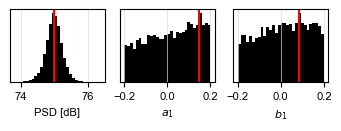

In [49]:
m_true_J = np.array([75, a_true[1], b_true[1]])
labels = [r"PSD [dB]", r"$a_1$", r"$b_1$"]
scales = [1.0, 1.0, 1.0]
n      = len(labels)
fig, axs = plt.subplots(nrows=1, ncols=n, figsize=(1.1*n, 1.2),
                            facecolor='white', layout='constrained')
axs = np.atleast_1d(axs)
for i, (ax, lab, sc) in enumerate(zip(axs, labels, scales)):
    ax.hist(sc*m[:,i], bins=30, color='k', zorder=1)
    if m_true is not None:
        ax.axvline(sc*m_true_J[i], color='r', lw=1.5, zorder=2)
    ax.set_xlabel(lab, fontsize=small)
    ax.set_yticks([])
    ax.tick_params(labelsize=small)
    ax.grid(color='gainsboro', linewidth=0.5, zorder=0)
fig.show()

In [160]:
#________ INVERSION (TRIAD) ________#

#__ Signal listings __
sigs_T  = ['normal']
sigs_J  = [{'sig':'noise2D', 's':s0, 'max_order':1}]
sigs_TJ = [*sigs_T, *sigs_J]

#__ Set up array covariance models __
# model_T  = modelling.ArrayCovarianceModel(x, freq, sigs_T)
# model_J  = modelling.ArrayCovarianceModel(x, freq, sigs_J)
model_TJ = modelling.ArrayCovarianceModel(x, freq, sigs_TJ, calc_noise_only=True)
print("Set up forward models.")

#__ Set prior bounds __
lower_T  = np.array([50.,  -5.7e-4, 2.3e-5, 1.0e-6, 1.0e-6, -0.99])
upper_T  = np.array([100., -3.6e-4, 2.3e-4, 5.0e-5, 5.0e-5,  0.99])
# lower_T = np.array([80., m_true[1]-1e-4, m_true[2]-1e-4, 1e-6,   1e-6,   -0.99])
# upper_T = np.array([100., m_true[1]+1e-4, m_true[2]+1e-4, 5e-5,  5e-5,    0.99])
lower_J  = np.array([50., -0.2, -0.2])
upper_J  = np.array([100., 0.2,  0.2])
lower_TJ = np.array([*lower_T, *lower_J])
upper_TJ = np.array([*upper_T, *upper_J])

#__ Set up prior pdf __
# prior_T  = inversion.Uniform(lower_T,  upper_T)
# prior_J  = inversion.Uniform(lower_J,  upper_J)
prior_TJ = inversion.Uniform(lower_TJ, upper_TJ)
print("Set up prior pdfs.")

#__ Set up posterior pdf __
# posterior_T  = inversion.Posterior(Gamma_T,  Nobs_T,       model_T,  prior_T)
# posterior_J  = inversion.Posterior(Gamma_J,  Nobs_J, model_J,  prior_J)
posterior_TJ = inversion.Posterior(Gamma_TJ, Nobs_T,       model_TJ, prior_TJ, Gamma_J, Nobs_J)

#__ Set up normalising flow models __
N_flow = 8
# flow_T  = inversion.LinearFlowsModel(len(lower_T),  N_flow, (lower_T,  upper_T))
# flow_J  = inversion.LinearFlowsModel(len(lower_J),  N_flow, (lower_J,  upper_J))
flow_TJ = inversion.LinearFlowsModel(len(lower_TJ), N_flow, (lower_TJ, upper_TJ))
print("Set up flow models.")

#__ Set up inversions __
learning_rate = 5e-4
outpath       = None
# inverse_T  = inversion.VI(flow_T,  posterior_T, learning_rate, outpath)
# inverse_J  = inversion.VI(flow_J,  posterior_J, learning_rate, outpath)
inverse_TJ = inversion.VI(flow_TJ, posterior_TJ, learning_rate, outpath)

#__ Inversion parameters __
iterations = 15000
nsample    = 200
nout       = int(1e-3*iterations)
save       = False
verbose    = True

#__ Invert __
print("Inverting ...")
# inverse_T.invert(iterations, nsample, nout, save, verbose)
print("    Inverted signal-only model.")
# inverse_J.invert(iterations, nsample, nout, save, verbose)
print("    Inverted noise-only model.")
inverse_TJ.invert(iterations, nsample, nout, save, verbose)
print("    Inverted signal-with-noise model.")

#__ Extract samples __
N_samples = 5000
# m_T       = inverse_T.sample(N_samples)
# m_J       = inverse_J.sample(N_samples)
m_TJ      = inverse_TJ.sample(N_samples)
print("Sampled posterior pdfs.")

Set up forward models.
Set up prior pdfs.
Set up flow models.
Inverting ...
    Inverted signal-only model.
    Inverted noise-only model.
----------------------------------------

Iteration:     0,	Loss:   51372.88
The elapsed time is: 0.06 s
Iteration:  1000,	Loss:   11885.46
The elapsed time is: 18.47 s
Iteration:  2000,	Loss:   11637.72
The elapsed time is: 34.79 s
Iteration:  3000,	Loss:   11354.33
The elapsed time is: 55.86 s
Iteration:  4000,	Loss:   11141.21
The elapsed time is: 72.47 s
Iteration:  5000,	Loss:   11040.51
The elapsed time is: 88.57 s
Iteration:  6000,	Loss:   11008.98
The elapsed time is: 106.45 s
Iteration:  7000,	Loss:   10994.55
The elapsed time is: 122.78 s
Iteration:  8000,	Loss:   10985.45
The elapsed time is: 138.89 s
Iteration:  9000,	Loss:   10982.33
The elapsed time is: 156.96 s
Iteration: 10000,	Loss:   10979.80
The elapsed time is: 173.26 s
Iteration: 11000,	Loss:   10979.17
The elapsed time is: 189.46 s
Iteration: 12000,	Loss:   10978.87
The elapsed

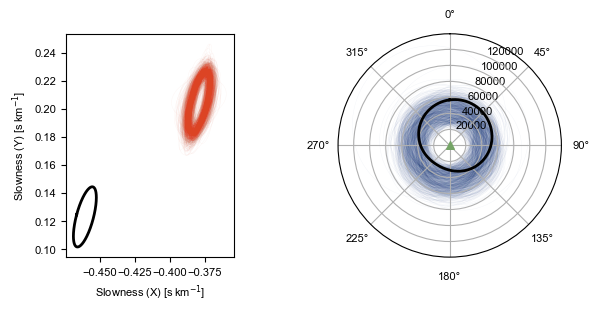

In [142]:
#________ PLOT ________#

#__ Ellipse helpers __
def mahalanobis_ellipse(mean, C, q=2*np.log(2), n=400):
    """Ellipse where (s-mean)^T C^-1 (s-mean) = q."""
    vals, vecs = np.linalg.eigh(C)
    t   = np.linspace(0, 2*np.pi, n)
    pts = np.column_stack([np.cos(t), np.sin(t)]) * np.sqrt(q) * np.sqrt(vals)[None,:]
    return np.asarray(mean)[None,:] + pts @ vecs.T

def cov_from_params(sig_x, sig_y, rho):
    return np.array([[sig_x**2,        rho*sig_x*sig_y],
                     [rho*sig_x*sig_y, sig_y**2       ]])

#__ Harmonic bases (rebuilt to match the simulation) __
order2D = np.arange(len(a_true))
cos_2D  = np.cos(order2D[None,:] * az[:,None])
sin_2D  = np.sin(order2D[None,:] * az[:,None])
e_m     = np.ones(len(order2D)); e_m[1:] = 2.0

#__ Create figure and axes __
fig = plt.figure(figsize=(6,3), facecolor='white', layout='constrained')
axs = [
    fig.add_subplot(1, 2, 1),
    fig.add_subplot(1, 2, 2, projection='polar')
]

#__ True signal moments (centre sensor) __
xi_true = m_true_T[1:3]
C_true  = cov_from_params(*m_true_T[3:6])

#__ Plot signal estimates __
N_show = min(1000, len(m_T))
for j in range(N_show):
    E = mahalanobis_ellipse(m_T[j,1:3], cov_from_params(*m_T[j,3:6]))
    axs[0].plot(1e3*E[:,0], 1e3*E[:,1], c=theme[0], lw=0.3, alpha=0.05, zorder=1)

#__ Plot true signal __
E_true = mahalanobis_ellipse(xi_true, C_true)
axs[0].plot(1e3*E_true[:,0], 1e3*E_true[:,1], c='k', lw=2.0, zorder=3)

#__ Plot noise estimates __
J_dB_hat, a1_hat, b1_hat = m_J[:,0], m_J[:,1], m_J[:,2]
J_Pa_hat = 10 ** (J_dB_hat/10)
a_hat = np.column_stack([np.ones_like(a1_hat), a1_hat])
b_hat = np.column_stack([np.zeros_like(b1_hat), b1_hat])
energy_J_hat  = np.sum(e_m[None,None,:] * (a_hat[:,None,:]*cos_2D[None,:,:]
                                           + b_hat[:,None,:]*sin_2D[None,:,:]), axis=2)
energy_J_hat *= J_Pa_hat[:,None] / np.nansum(energy_J_hat, axis=1, keepdims=True)
for j in range(N_show):
    axs[1].plot(az, energy_J_hat[j], lw=0.3, alpha=0.05, color=theme[2], zorder=1)

#__ Plot true noise __
axs[1].plot(az, energy_J, lw=2.0, color='k', zorder=2)
axs[1].scatter(0, 0, marker='^', c=theme[1], s=30, zorder=3)
axs[1].set_theta_zero_location('N')
axs[1].set_theta_direction(-1)

#__ Format __
axs[0].set_aspect('equal')
axs[0].set_xlabel(r"Slowness (X) [s$\,$km$^{-1}$]", fontsize=small)
axs[0].set_ylabel(r"Slowness (Y) [s$\,$km$^{-1}$]", fontsize=small)
axs[0].tick_params(labelsize=small)
axs[1].tick_params(labelsize=small)

#__ Show figure __
fig.show()

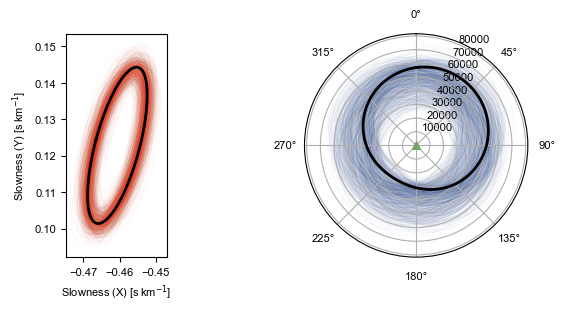

In [161]:
#________ PLOT ________#

#__ Ellipse helpers __
def mahalanobis_ellipse(mean, C, q=2*np.log(2), n=400):
    """Ellipse where (s-mean)^T C^-1 (s-mean) = q."""
    vals, vecs = np.linalg.eigh(C)
    t   = np.linspace(0, 2*np.pi, n)
    pts = np.column_stack([np.cos(t), np.sin(t)]) * np.sqrt(q) * np.sqrt(vals)[None,:]
    return np.asarray(mean)[None,:] + pts @ vecs.T

def cov_from_params(sig_x, sig_y, rho):
    return np.array([[sig_x**2,        rho*sig_x*sig_y],
                     [rho*sig_x*sig_y, sig_y**2       ]])

#__ Harmonic bases (rebuilt to match the simulation) __
order2D = np.arange(len(a_true))
cos_2D  = np.cos(order2D[None,:] * az[:,None])
sin_2D  = np.sin(order2D[None,:] * az[:,None])
e_m     = np.ones(len(order2D)); e_m[1:] = 2.0

#__ Create figure and axes __
fig = plt.figure(figsize=(6,3), facecolor='white', layout='constrained')
axs = [
    fig.add_subplot(1, 2, 1),
    fig.add_subplot(1, 2, 2, projection='polar')
]

#__ True signal moments (centre sensor) __
xi_true = m_true_T[1:3]
C_true  = cov_from_params(*m_true_T[3:6])

#__ Plot signal estimates __
N_show = min(1000, len(m_TJ))
for j in range(N_show):
    E = mahalanobis_ellipse(m_TJ[j,1:3], cov_from_params(*m_TJ[j,3:6]))
    axs[0].plot(1e3*E[:,0], 1e3*E[:,1], c=theme[0], lw=0.3, alpha=0.05, zorder=1)

#__ Plot true signal __
E_true = mahalanobis_ellipse(xi_true, C_true)
axs[0].plot(1e3*E_true[:,0], 1e3*E_true[:,1], c='k', lw=2.0, zorder=3)

#__ Plot noise estimates __
J_dB_hat, a1_hat, b1_hat = m_TJ[:,6], m_TJ[:,7], m_TJ[:,8]
J_Pa_hat = 10 ** (J_dB_hat/10)
a_hat = np.column_stack([np.ones_like(a1_hat), a1_hat])
b_hat = np.column_stack([np.zeros_like(b1_hat), b1_hat])
energy_J_hat  = np.sum(e_m[None,None,:] * (a_hat[:,None,:]*cos_2D[None,:,:]
                                           + b_hat[:,None,:]*sin_2D[None,:,:]), axis=2)
energy_J_hat *= J_Pa_hat[:,None] / np.nansum(energy_J_hat, axis=1, keepdims=True)
for j in range(N_show):
    axs[1].plot(az, energy_J_hat[j], lw=0.3, alpha=0.05, color=theme[2], zorder=1)

#__ Plot true noise __
axs[1].plot(az, energy_J, lw=2.0, color='k', zorder=2)
axs[1].scatter(0, 0, marker='^', c=theme[1], s=30, zorder=3)
axs[1].set_theta_zero_location('N')
axs[1].set_theta_direction(-1)

#__ Format __
axs[0].set_aspect('equal')
axs[0].set_xlabel(r"Slowness (X) [s$\,$km$^{-1}$]", fontsize=small)
axs[0].set_ylabel(r"Slowness (Y) [s$\,$km$^{-1}$]", fontsize=small)
axs[0].tick_params(labelsize=small)
axs[1].tick_params(labelsize=small)

#__ Show figure __
fig.show()

In [158]:
freq / (2*np.pi)

array([3.96850263, 5.        , 6.29960525])

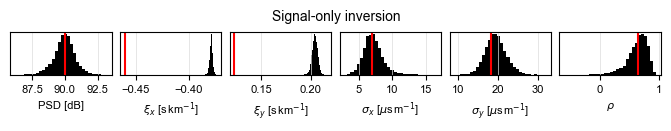

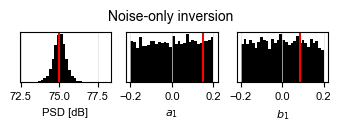

In [146]:
#________ PLOT POSTERIORS ________#

def plot_posteriors(m, m_true, labels, scales, title, nbins=30):
    """Histogram each posterior parameter with its true value overlaid."""
    n = len(labels)
    fig, axs = plt.subplots(nrows=1, ncols=n, figsize=(1.1*n, 1.2),
                            facecolor='white', layout='constrained')
    axs = np.atleast_1d(axs)
    for i, (ax, lab, sc) in enumerate(zip(axs, labels, scales)):
        ax.hist(sc*m[:,i], bins=nbins, color='k', zorder=1)
        if m_true is not None:
            ax.axvline(sc*m_true[i], color='r', lw=1.5, zorder=2)
        ax.set_xlabel(lab, fontsize=small)
        ax.set_yticks([])
        ax.tick_params(labelsize=small)
        ax.grid(color='gainsboro', linewidth=0.5, zorder=0)
    fig.suptitle(title, fontsize=large)
    return fig, axs

#__ Signal __
labels_T = [r"PSD [dB]", r"$\xi_x$ [s$\,$km$^{-1}$]", r"$\xi_y$ [s$\,$km$^{-1}$]",
            r"$\sigma_x$ [$\mu$s$\,$m$^{-1}$]", r"$\sigma_y$ [$\mu$s$\,$m$^{-1}$]", r"$\rho$"]
scales_T = [1.0, 1e3, 1e3, 1e6, 1e6, 1.0]
plot_posteriors(m_T, m_true_T, labels_T, scales_T, "Signal-only inversion")

#__ Noise __
m_true_J = np.array([J_dB, a_true[1], b_true[1]])
labels_J = [r"PSD [dB]", r"$a_1$", r"$b_1$"]
scales_J = [1.0, 1.0, 1.0]
plot_posteriors(m_J, m_true_J, labels_J, scales_J, "Noise-only inversion")

plt.show()

In [148]:
print(m_T[:,1:3].mean(axis=0) - m_true_T[1:3])
print('|offset| =', np.linalg.norm(m_T[:,1:3].mean(axis=0) - m_true_T[1:3]))

[8.14138287e-05 8.14690645e-05]
|offset| = 0.00011517560490751477


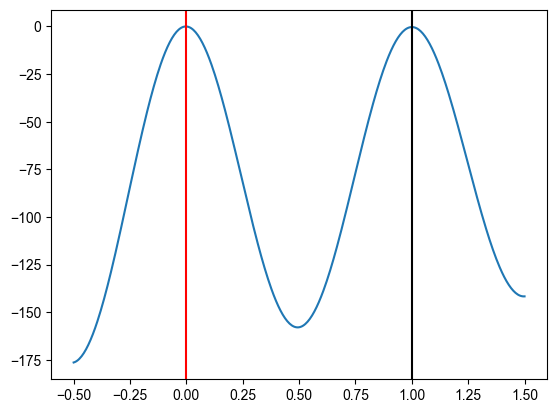

In [150]:
d = m_T[:,1:6].mean(axis=0) - m_true_T[1:6]
lam = np.linspace(-0.5, 1.5, 400)
M = m_true_T[None,:] + lam[:,None]*np.concatenate([[0.], d])[None,:]
ll = np.array([posterior_T.log_likelihood(M[[i]], grad=False)[0] for i in range(len(lam))])
plt.plot(lam, ll - ll.max()); plt.axvline(0, c='r'); plt.axvline(1, c='k')

ValueError: operand has more dimensions than subscripts given in einstein sum, but no '...' ellipsis provided to broadcast the extra dimensions.

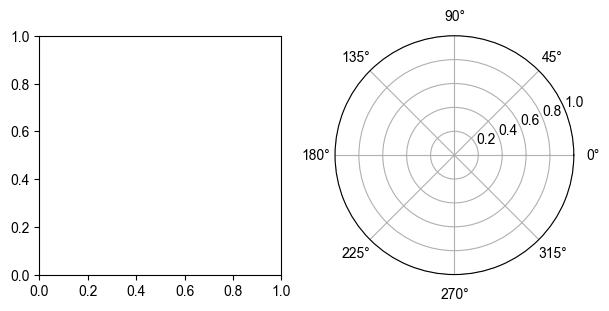

In [131]:
#________ PLOT ________#

#__ Ellipse helper __
def mahalanobis_ellipse(mean, C, q=2*np.log(2), n=400):
    """Ellipse where (s-mean)^T C^-1 (s-mean) = q."""
    vals, vecs = np.linalg.eigh(C)
    t   = np.linspace(0, 2*np.pi, n)
    pts = np.column_stack([np.cos(t), np.sin(t)]) * np.sqrt(q) * np.sqrt(vals)[None,:]
    return np.asarray(mean)[None,:] + pts @ vecs.T

def cov_from_params(sig_x, sig_y, rho):
    return np.array([[sig_x**2,        rho*sig_x*sig_y],
                     [rho*sig_x*sig_y, sig_y**2       ]])

#__ Create figure and axes __
fig = plt.figure(figsize=(6,3), facecolor='white', layout='constrained')
axs = [
    fig.add_subplot(1, 2, 1),
    fig.add_subplot(1, 2, 2, projection='polar')
]

#__ Moments of the true slowness distribution __
w       = np.nan_to_num(energy_T,   nan=0.0)   # (source, mode)
s       = np.nan_to_num(slowness_T, nan=0.0)   # (source, mode, direction)
W       = w.sum()
xi_true = np.einsum('pq,pql->l', w, s) / W
ds      = s - xi_true
C_true  = np.einsum('pq,pql,pqm->lm', w, ds, ds) / W

#__ Plot signal estimates __
N_show = 1000
for j in range(N_show):
    E = mahalanobis_ellipse(m_T[j,1:3], cov_from_params(*m_T[j,3:6]))
    axs[0].plot(1e3*E[:,0], 1e3*E[:,1], c=theme[0], lw=0.3, alpha=0.05, zorder=1)

#__ Plot true signal __
E_true = mahalanobis_ellipse(xi_true, C_true)
axs[0].plot(1e3*E_true[:,0], 1e3*E_true[:,1], c='k', lw=2.0, zorder=3)

#__ Plot noise estimates __
T_dB_hat, a1_hat, b1_hat = m_J[:,0], m_J[:,1], m_J[:,2]
T_Pa_hat = 10 ** (T_dB_hat/10)
a_hat = np.column_stack([np.ones_like(a1_hat), a1_hat])
b_hat = np.column_stack([np.zeros_like(b1_hat), b1_hat])
energy_J_hat  = np.sum(e_m[None,None,:] * (a_hat[:,None,:]*cos_2D[None,:,:]
                                           + b_hat[:,None,:]*sin_2D[None,:,:]), axis=2)
energy_J_hat *= T_Pa_hat[:,None] / np.nansum(energy_J_hat, axis=1, keepdims=True)
for j in range(N_show):
    axs[1].plot(az, energy_J_hat[j], lw=0.3, alpha=0.05, color=theme[2], zorder=1)

#__ Plot true noise __
axs[1].plot(az, energy_J, lw=2.0, color='k', zorder=2)
axs[1].scatter(0, 0, marker='^', c=theme[1], s=30, zorder=3)
axs[1].set_theta_zero_location('N')
axs[1].set_theta_direction(-1)

#__ Format __
axs[0].set_aspect('equal')
axs[0].set_xlabel(r"Slowness (X) [s$\,$km$^{-1}$]", fontsize=small)
axs[0].set_ylabel(r"Slowness (Y) [s$\,$km$^{-1}$]", fontsize=small)
axs[0].tick_params(labelsize=small)
axs[1].tick_params(labelsize=small)

#__ Show figure __
fig.show()

In [ ]:
#________ PLOT ________#

#__ Ellipse helper __
def mahalanobis_ellipse(mean, C, q=2*np.log(2), n=400):
    """Ellipse where (s-mean)^T C^-1 (s-mean) = q."""
    vals, vecs = np.linalg.eigh(C)
    t   = np.linspace(0, 2*np.pi, n)
    pts = np.column_stack([np.cos(t), np.sin(t)]) * np.sqrt(q) * np.sqrt(vals)[None,:]
    return np.asarray(mean)[None,:] + pts @ vecs.T

def cov_from_params(sig_x, sig_y, rho):
    return np.array([[sig_x**2,        rho*sig_x*sig_y],
                     [rho*sig_x*sig_y, sig_y**2       ]])

#__ Create figure and axes __
fig = plt.figure(figsize=(6,3), facecolor='white', layout='constrained')
axs = [
    fig.add_subplot(1, 2, 1),
    fig.add_subplot(1, 2, 2, projection='polar')
]

#__ Moments of the true slowness distribution __
w       = np.nan_to_num(energy_T,   nan=0.0)   # (source, mode)
s       = np.nan_to_num(slowness_T, nan=0.0)   # (source, mode, direction)
W       = w.sum()
xi_true = np.einsum('pq,pql->l', w, s) / W
ds      = s - xi_true
C_true  = np.einsum('pq,pql,pqm->lm', w, ds, ds) / W

#__ Plot signal estimates __
N_show = 1000
for j in range(N_show):
    E = mahalanobis_ellipse(m_TJ[j,1:3], cov_from_params(*m_TJ[j,3:6]))
    axs[0].plot(1e3*E[:,0], 1e3*E[:,1], c=theme[0], lw=0.3, alpha=0.05, zorder=1)

#__ Plot true signal __
E_true = mahalanobis_ellipse(xi_true, C_true)
axs[0].plot(1e3*E_true[:,0], 1e3*E_true[:,1], c='k', lw=2.0, zorder=3)

#__ Plot noise estimates __
T_dB_hat, a1_hat, b1_hat = m_JJ[:,7], m_TJ[:,8], m_T[:,9]
T_Pa_hat = 10 ** (T_dB_hat/10)
a_hat = np.column_stack([np.ones_like(a1_hat), a1_hat])
b_hat = np.column_stack([np.zeros_like(b1_hat), b1_hat])
energy_J_hat  = np.sum(e_m[None,None,:] * (a_hat[:,None,:]*cos_2D[None,:,:]
                                           + b_hat[:,None,:]*sin_2D[None,:,:]), axis=2)
energy_J_hat *= T_Pa_hat[:,None] / np.nansum(energy_J_hat, axis=1, keepdims=True)
for j in range(N_show):
    axs[1].plot(az, energy_J_hat[j], lw=0.3, alpha=0.05, color=theme[2], zorder=1)

#__ Plot true noise __
axs[1].plot(az, energy_J, lw=2.0, color='k', zorder=2)
axs[1].scatter(0, 0, marker='^', c=theme[1], s=30, zorder=3)
axs[1].set_theta_zero_location('N')
axs[1].set_theta_direction(-1)

#__ Format __
axs[0].set_aspect('equal')
axs[0].set_xlabel(r"Slowness (X) [s$\,$km$^{-1}$]", fontsize=small)
axs[0].set_ylabel(r"Slowness (Y) [s$\,$km$^{-1}$]", fontsize=small)
axs[0].tick_params(labelsize=small)
axs[1].tick_params(labelsize=small)

#__ Show figure __
fig.show()

Loaded signal-field.
Calculated noise-field intensity.
Scaled field intensities.


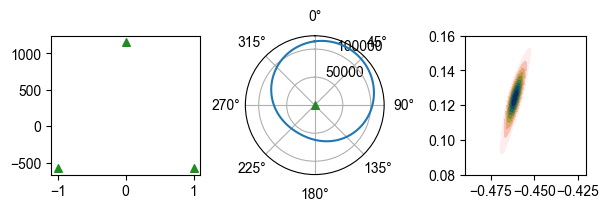

In [45]:
#________ SIMULATED WAVEFIELD ________#

#__ Read absyssal T-phase simulation __
with h5py.File('abyssal_T-phase_sim.h5', 'r') as hf:

    #__ Data __
    slowness_T = hf['data/slowness_vector'][:]        # Slowness vector [m.s-1] (frequency, source, mode, direction)
    energy_T   = hf['data/energy'][:]                 # Unscaled signal-field energy (frequency, source, mode)
    s0         = np.linalg.norm(slowness_T[0,0,0,:])  # Slowness of fundamental mode [s.m-1]

    #__ Coordinates __
    f     = hf['coordinates/frequency'][:]  # Frequency vector [Hz] (frequency)
    xR    = hf['coordinates/xR'][:]         # Receiver location [m] (receiver, direction)

#__ Print statement __
print(f"Loaded signal-field.")

#__ Harmonic noise parameters __
a = np.array([1., 0.1480])  # Cosine coefficient (order)
b = np.array([0., 0.0854])  # Sine coefficient (order)
Nsrc = 360

#__ Harmonic noise bases __
az        = np.arange(0, 2*np.pi, 2*np.pi/Nsrc)   # Source azimuth (source)
max_order = len(a) - 1                            # Maximum cylindrical harmonic order
order2D   = np.arange(max_order + 1)              # Cylindrical-harmonic order vector (order)
cos_2D    = np.cos(order2D[None,:] * az[:,None])  # Cylindrical-harmonic cosine basis (source, order)
sin_2D    = np.sin(order2D[None,:] * az[:,None])  # Cylindrical-harmonic sine basis (source, order)
e_m       = np.ones(len(order2D), dtype=float)    # Cylindrical-harmonic cosine/sine normalization factors (order)
e_m[1:]   = 2.0

#__ Harmonic noise intensity __
energy_J   = np.sum(e_m[None,:] * (a[None,:]*cos_2D + b[None,:]*sin_2D), axis=1)  # Unscaled noise-field energy (source)
slowness_J = s0 * np.column_stack([np.cos(az), np.sin(az)])                      # Slowness vector [s.m-1] (source)

#__ Print statement __
print("Calculated noise-field intensity.")

#__ Power parameters __
T_dB = 90.0  # Signal PSD [dB : 1 uPa2.Hz-1]
J_dB = 75.0  # Harmonic noise PSD [dB : 1 uPa2.Hz-1]

#__ Scale intensities __
T_Pa = 10**(T_dB/10)  # Signal PSD [uPa2.Hz-1]
J_Pa = 10**(J_dB/10)  # Harmonic noise PSD [uPa2.Hz-1]
energy_T *= T_Pa / np.nansum(energy_T, axis=(1,2), keepdims=True)  # Scaled signal-field energy [uPa2.Hz-1] (frequency, source, mode)
energy_J *= J_Pa / np.nansum(energy_J, axis=0,     keepdims=True)  # Scaled signal-field energy [uPa2.Hz-1] (source)

#__ Print statement __
print("Scaled field intensities.")

#________ PLOT ________#

#__ Create figure and axes __
fig = plt.figure(figsize=(6,2), facecolor='white', layout='constrained')
axs = [
    fig.add_subplot(1, 3, 1),
    fig.add_subplot(1, 3, 2, projection='polar'),
    fig.add_subplot(1, 3, 3),
]

#__ Plot receiver array __
axs[0].scatter(xR[1:,0], xR[1:,1], marker='^', c='forestgreen', s=30)

#__ Plot noise distribution __
axs[1].plot(az, energy_J)
axs[1].scatter(0, 0, marker='^', c='forestgreen', s=30, zorder=3)
axs[1].set_theta_zero_location('N')
axs[1].set_theta_direction(-1)

#__ Set up slowness grid __
s_max = 7.0e-4
Ns    = 200
gx, gy = np.meshgrid(
    np.linspace(-0.49e-3,-0.41e-3, Ns),
    np.linspace(0.08e-3, 0.16e-3, Ns),
    indexing='ij'
)
grid_pts = np.vstack([gx.ravel(), gy.ravel()])
density  = np.zeros((len(f), Ns, Ns))

#__ Calculate energy density __
i_freq = 0
keep  = ~np.isnan(slowness_T[i_freq, 0, :, 0])   # finite modes at this frequency
sx_i  = slowness_T[i_freq][:, keep, 0].ravel()
sy_i  = slowness_T[i_freq][:, keep, 1].ravel()
w_i   = energy_T[i_freq][:, keep].ravel()

good = w_i > 1e-12 * w_i.max()
if good.sum() < 3:
    print(f'f={f[i_freq]:.1f} Hz: only {good.sum()} live points, skipping')
else:
    kde = gaussian_kde(np.vstack([sx_i[good], sy_i[good]]), weights=w_i[good])
    density[i_freq] = kde(grid_pts).reshape(Ns, Ns) * w_i[good].sum()

#__ Plot energy density __
d = density[i_freq] / density[i_freq].max()
im_2 = axs[2].contourf(
    1e3*gx, 1e3*gy, d,
    levels=np.arange(0.1, 1.0+0.1, 0.1), cmap='cmc.batlowW_r',
    zorder=1
)
axs[2].set_aspect('equal')
axs[2].set_xlim(-0.49,-0.42)
axs[2].set_ylim(0.08,0.16)

fig.show()

In [123]:
xR

array([[ 0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00,  1.15470054e+03],
       [-1.00000000e+00, -5.77350269e+02],
       [ 1.00000000e+00, -5.77350269e+02]])

In [46]:
#________ CONSTRUCT ARRAY-COVARIANCE MATRIX (TRIPLET) ________#

#__ Sensor separation __
x    = xR#[1:]                     # Sensor position (sensor, direction)
r    = x[None,:,:] - x[:,None,:]  # Sensor separation (sensor, sensor, position)
freq = 2 * np.pi * f              # Angular frequency vector [rad.s-1] (frequency)

#__ Array covariance matrix __
Gamma_T  = np.einsum(         # Array covariance of signal
    'ipq,ipqjk->ijk',
    np.nan_to_num(energy_T, nan=0.0),
    np.exp(1j * np.einsum('i,jkl,ipql->ipqjk',freq,r,np.nan_to_num(slowness_T, nan=0.0)))
)
Gamma_J  = np.einsum(         # Array covariance of noise
    'p,ipjk->ijk',
    energy_J,
    np.exp(1j * np.einsum('i,jkl,pl->ipjk',freq,r,slowness_J))
)
Gamma_TJ = Gamma_T + Gamma_J  # Full array covariance (frequency, sensor, sensor)

#__ Number of observations __
N_obs       = 16
N_obs_noise = 32

#__ Print statement __
print("Constructed array covariance matrix.")

Constructed array covariance matrix.


Set up inversion.
----------------------------------------

Iteration:     0,	Loss:    6565.61
The elapsed time is: 0.01 s
Iteration:  1000,	Loss:    2163.75
The elapsed time is: 5.08 s
Iteration:  2000,	Loss:    2133.76
The elapsed time is: 10.15 s
Iteration:  3000,	Loss:    2128.08
The elapsed time is: 15.17 s
Iteration:  4000,	Loss:    2122.28
The elapsed time is: 20.15 s
Iteration:  5000,	Loss:    2117.61
The elapsed time is: 25.13 s
Iteration:  6000,	Loss:    2117.11
The elapsed time is: 30.09 s
Iteration:  7000,	Loss:    2116.90
The elapsed time is: 35.05 s
Iteration:  8000,	Loss:    2116.68
The elapsed time is: 40.00 s
Iteration:  9000,	Loss:    2116.82
The elapsed time is: 44.95 s
Iteration: 10000,	Loss:    2116.72
The elapsed time is: 49.94 s
Iteration: 11000,	Loss:    2116.70
The elapsed time is: 55.32 s
Iteration: 12000,	Loss:    2116.72
The elapsed time is: 60.53 s
Iteration: 13000,	Loss:    2116.78
The elapsed time is: 65.63 s
Iteration: 14000,	Loss:    2116.64
The elapsed

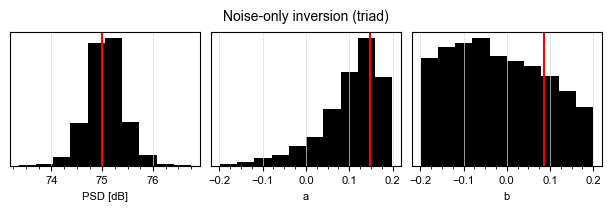

In [48]:
#________ INVERSION (NOISE ONLY) ________#

#__ Set up array-covariance model __
signal_types = [{'sig':'noise2D', 's':s0, 'max_order':1}]
arraycovariance_model = modelling.ArrayCovarianceModel(x, freq, signal_types)

#__ Set up prior distribution __
lower = np.array([50.,  -0.2, -0.2])  # Matrix not positive definite if ill-defined!
upper = np.array([100., 0.2,  0.2])
prior = inversion.Uniform(lower, upper)

#__ Set up posterior distribution __
posterior = inversion.Posterior(Gamma_J, N_obs_noise, arraycovariance_model, prior)

#__ Set up normalising flows model __
N_param    = 3  # Number of model parameters
N_flow     = 8  # Number of normalising flows
flow_model = inversion.LinearFlowsModel(N_param, N_flow, (lower, upper))

#__ Set up inversion (can take a minute on first initialisation) __
learning_rate = 1e-3
outpath       = './models/noise_only'
inverse_problem = inversion.VI(flow_model, posterior, learning_rate, outpath)

#__ Print statement __
print("Set up inversion.")

#__ Perform inversion __
iterations = 15000
nsample    = 8
nout       = 15
save_intermediate_result = False
verbose    = True
inverse_problem.invert(iterations, nsample, nout, save_intermediate_result, verbose)

#__ Print statement __
print("Completed inversion.")

#__ Extract samples __
m = inverse_problem.sample(5000)

#__ Plot __
fig, axs = plt.subplots(
    nrows=1, ncols=3,
    figsize=(6,2), facecolor='white', layout='constrained'
)
for ax, xlims, ylims, xmajmin, ymajmin in zip(axs,
    [None, None, None],
    [None, None, None],
    [(1,0.25), (0.1,0.025), (0.1,0.025)],
    [None, None, None]
):
    if xlims: ax.set_xlim(*xlims)
    if ylims: ax.set_ylim(*ylims)
    if xmajmin:
        ax.xaxis.set_major_locator(ticker.MultipleLocator(xmajmin[0]))
        ax.xaxis.set_minor_locator(ticker.MultipleLocator(xmajmin[1]))
    if ymajmin:
        ax.yaxis.set_major_locator(ticker.MultipleLocator(ymajmin[0]))
        ax.yaxis.set_minor_locator(ticker.MultipleLocator(ymajmin[1]))
    ax.tick_params(labelsize=small)
    ax.grid(color='gainsboro', linewidth=0.5)
    ax.set_yticks([])
for ax, xlab, ylab in zip(axs,
    ["PSD [dB]", "a", "b"],
    [None,None,None]
):
    if xlab: ax.set_xlabel(xlab, fontsize=small)
    if ylab: ax.set_ylabel(ylab, fontsize=small)
fig.suptitle("Noise-only inversion (triad)", fontsize=large)
for i, (ax, mi) in enumerate(zip(axs, [J_dB,a[1],b[1]])):
    ax.hist(m[:,i], color='k', zorder=1)
    ax.axvline(mi, color='r', zorder=2)
fig.show()

Set up inversion.
----------------------------------------

Iteration:     0,	Loss: 1418578.16
The elapsed time is: 0.01 s
Iteration:  1000,	Loss:    5715.40
The elapsed time is: 13.74 s
Iteration:  2000,	Loss:    1386.14
The elapsed time is: 26.83 s
Iteration:  3000,	Loss:    1266.69
The elapsed time is: 41.02 s
Iteration:  4000,	Loss:    1228.60
The elapsed time is: 55.54 s
Iteration:  5000,	Loss:    1221.67
The elapsed time is: 68.89 s
Iteration:  6000,	Loss:    1232.24
The elapsed time is: 82.45 s
Iteration:  7000,	Loss:    1203.58
The elapsed time is: 95.81 s
Iteration:  8000,	Loss:    1199.32
The elapsed time is: 109.04 s
Iteration:  9000,	Loss:    1190.72
The elapsed time is: 122.82 s
Iteration: 10000,	Loss:    1158.88
The elapsed time is: 136.20 s
Iteration: 11000,	Loss:    1139.66
The elapsed time is: 149.71 s
Iteration: 12000,	Loss:    1135.44
The elapsed time is: 163.64 s
Iteration: 13000,	Loss:    1127.07
The elapsed time is: 177.79 s
Iteration: 14000,	Loss:    1113.86
The 

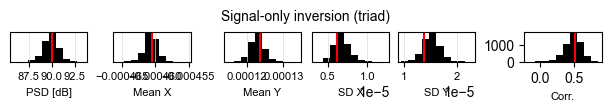

In [73]:
#________ TEST GEOMETRY ________#

#__ Set up array-covariance model __
signal_types = ['normal']
arraycovariance_model = modelling.ArrayCovarianceModel(x, freq, signal_types)

#__ Set up prior distribution __
# lower = np.array([50.,  -0.9e-3, -0.9e-3, 0.1e-5, 0.1e-5, -0.99])
# upper = np.array([100., 0.9e-3,  0.9e-3, 0.2e-3, 0.2e-3, 0.99])
lower = np.array([80., m_true[1]-1e-4, m_true[2]-1e-4, 1e-6,   1e-6,   -0.99])
upper = np.array([100., m_true[1]+1e-4, m_true[2]+1e-4, 5e-5,  5e-5,    0.99])
prior = inversion.Uniform(lower, upper)

#__ Set up posterior distribution __
posterior = inversion.Posterior(Gamma_T, N_obs, arraycovariance_model, prior)

#__ Set up normalising flows model __
N_param    = len(lower)  # Number of model parameters
N_flow     = 8  # Number of normalising flows
flow_model = inversion.LinearFlowsModel(N_param, N_flow, (lower, upper))

#__ Set up inversion (can take a minute on first initialisation) __
learning_rate = 5e-4  # Decrease if dodgy posterior
outpath       = './models/noise_only'
inverse_problem = inversion.VI(flow_model, posterior, learning_rate, outpath)

#__ Print statement __
print("Set up inversion.")

#__ Perform inversion __
iterations = 20000  # Increase if dodgy posterior
nsample    = 500  # Increase if dodgy posterior
nout       = 20
save_intermediate_result = False
verbose    = True
inverse_problem.invert(iterations, nsample, nout, save_intermediate_result, verbose)

#__ Extract samples __
m = inverse_problem.sample(5000)

#__ Plot __
fig, axs = plt.subplots(
    nrows=1, ncols=6,
    figsize=(6,1), facecolor='white', layout='constrained'
)
for ax, xlims, ylims, xmajmin, ymajmin in zip(axs,
    [None, None, None, None, None],
    [None, None, None, None, None],
    [None, None, None, None, None],
    [None, None, None, None, None]
):
    if xlims: ax.set_xlim(*xlims)
    if ylims: ax.set_ylim(*ylims)
    if xmajmin:
        ax.xaxis.set_major_locator(ticker.MultipleLocator(xmajmin[0]))
        ax.xaxis.set_minor_locator(ticker.MultipleLocator(xmajmin[1]))
    if ymajmin:
        ax.yaxis.set_major_locator(ticker.MultipleLocator(ymajmin[0]))
        ax.yaxis.set_minor_locator(ticker.MultipleLocator(ymajmin[1]))
    ax.tick_params(labelsize=small)
    ax.grid(color='gainsboro', linewidth=0.5)
    ax.set_yticks([])
for ax, xlab, ylab in zip(axs,
    ["PSD [dB]", "Mean X", "Mean Y", "SD X", "SD Y", "Corr."],
    [None,None,None,None,None,None]
):
    if xlab: ax.set_xlabel(xlab, fontsize=small)
    if ylab: ax.set_ylabel(ylab, fontsize=small)
fig.suptitle("Signal-only inversion (triad)", fontsize=large)
for i, (ax, mi) in enumerate(zip(axs, m_true)):
    ax.hist(m[:,i], color='k', zorder=1)
    ax.axvline(mi, color='r', zorder=2)
fig.show()

In [100]:
lower = np.array([80., m_true[1]-1e-4, m_true[2]-1e-4, 1e-6,   1e-6,   -0.99])
upper = np.array([100., m_true[1]+1e-4, m_true[2]+1e-4, 5e-5,  5e-5,    0.99])

In [106]:
upper

array([ 1.0000e+02, -3.6056e-04,  2.2346e-04,  5.0000e-05,  5.0000e-05,
        9.9000e-01])

In [116]:
#________ INVERSION (TRIAD) ________#

#__ Rotate array
def rotate_array(X, theta_deg, about=None):
    """Rotate array coordinates anticlockwise by theta_deg [deg]."""
    t = np.radians(theta_deg)
    R = np.array([[np.cos(t), -np.sin(t)],
                  [np.sin(t),  np.cos(t)]])
    c = np.zeros(2) if about is None else np.asarray(about, float)
    return (X - c) @ R.T + c
xR_rot = rotate_array(x[1:], 15.0)
r_rot = xR_rot[None,:,:] - xR_rot[:,None,:]
Gamma_T_rot  = np.einsum(         # Array covariance of signal
    'ipq,ipqjk->ijk',
    np.nan_to_num(energy_T, nan=0.0),
    np.exp(1j * np.einsum('i,jkl,ipql->ipqjk',freq,r_rot,np.nan_to_num(slowness_T, nan=0.0)))
)

#__ Signal listings __
sigs_T  = ['normal']
# sigs_J  = [{'sig':'noise2D', 's':s0, 'max_order':1}]
# sigs_TJ = [*sigs_T, *sigs_J]

#__ Set up array covariance models __
model_T  = modelling.ArrayCovarianceModel(xR_rot, freq, sigs_T)
# model_J  = modelling.ArrayCovarianceModel(x[1:], freq, sigs_J)
# model_TJ = modelling.ArrayCovarianceModel(x[1:], freq, sigs_TJ, calc_noise_only=True)
print("Set up forward models.")

#__ Set prior bounds __
# lower_T  = np.array([50.,  -5.7e-4, 2.3e-5, 1.0e-6, 1.0e-6, -0.99])
# upper_T  = np.array([100., -3.6e-4, 2.3e-4, 5.0e-5, 5.0e-5,  0.99])
lower_T = np.array([80., m_true[1]-1e-4, m_true[2]-1e-4, 1e-6,   1e-6,   -0.99])
upper_T = np.array([100., m_true[1]+1e-4, m_true[2]+1e-4, 5e-5,  5e-5,    0.99])
# lower_J  = np.array([50., -0.2, -0.2])
# upper_J  = np.array([100., 0.2,  0.2])
# lower_TJ = np.array([*lower_T, *lower_J])
# upper_TJ = np.array([*upper_T, *upper_J])

#__ Set up prior pdf __
prior_T  = inversion.Uniform(lower_T,  upper_T)
# prior_J  = inversion.Uniform(lower_J,  upper_J)
# prior_TJ = inversion.Uniform(lower_TJ, upper_TJ)
print("Set up prior pdfs.")

#__ Set up posterior pdf __
posterior_T  = inversion.Posterior(Gamma_T_rot,  N_obs,       model_T,  prior_T)
# posterior_J  = inversion.Posterior(Gamma_J[:,1:,1:],  N_obs_noise, model_J,  prior_J)
# posterior_TJ = inversion.Posterior(Gamma_TJ[:,1:,1:], N_obs,       model_TJ, prior_TJ, Gamma_J[:,1:,1:], N_obs_noise)

#__ Set up normalising flow models __
N_flow = 8
flow_T  = inversion.LinearFlowsModel(len(lower_T),  N_flow, (lower_T,  upper_T))
# flow_J  = inversion.LinearFlowsModel(len(lower_J),  N_flow, (lower_J,  upper_J))
# flow_TJ = inversion.LinearFlowsModel(len(lower_TJ), N_flow, (lower_TJ, upper_TJ))
print("Set up flow models.")

#__ Set up inversions __
learning_rate = 5e-4
outpath       = None
inverse_T  = inversion.VI(flow_T,  posterior_T, learning_rate, outpath)
# inverse_J  = inversion.VI(flow_J,  posterior_J, learning_rate, outpath)
# inverse_TJ = inversion.VI(flow_TJ, posterior_TJ, learning_rate, outpath)

#__ Inversion parameters __
iterations = 20000
nsample    = 500
nout       = int(1e-3*iterations)
save       = False
verbose    = True

#__ Invert __
print("Inverting ...")
inverse_T.invert(iterations, nsample, nout, save, verbose)
print("    Inverted signal-only model.")
# inverse_J.invert(iterations, nsample, nout, save, verbose)
print("    Inverted noise-only model.")
# inverse_TJ.invert(iterations, nsample, nout, save, verbose)
print("    Inverted signal-with-noise model.")

#__ Extract samples __
N_samples = 5000
m_T       = inverse_T.sample(N_samples)
# m_J       = inverse_J.sample(N_samples)
# m_TJ      = inverse_TJ.sample(N_samples)
print("Sampled posterior pdfs.")

Set up forward models.
Set up prior pdfs.
Set up flow models.
Inverting ...
----------------------------------------

Iteration:     0,	Loss:    2001.50
The elapsed time is: 0.13 s
Iteration:  1000,	Loss:     875.65
The elapsed time is: 14.80 s
Iteration:  2000,	Loss:     855.60
The elapsed time is: 29.36 s
Iteration:  3000,	Loss:     843.81
The elapsed time is: 44.50 s
Iteration:  4000,	Loss:     830.63
The elapsed time is: 59.20 s
Iteration:  5000,	Loss:     818.57
The elapsed time is: 73.59 s
Iteration:  6000,	Loss:     810.35
The elapsed time is: 88.01 s
Iteration:  7000,	Loss:     803.10
The elapsed time is: 102.61 s
Iteration:  8000,	Loss:     797.79
The elapsed time is: 117.16 s
Iteration:  9000,	Loss:     795.18
The elapsed time is: 131.56 s
Iteration: 10000,	Loss:     794.99
The elapsed time is: 146.03 s
Iteration: 11000,	Loss:     794.86
The elapsed time is: 162.86 s
Iteration: 12000,	Loss:     794.91
The elapsed time is: 177.13 s
Iteration: 13000,	Loss:     794.88
The elapse

In [111]:
#________ INVERSION (QUAD) ________#

#__ Signal listings __
sigs_T  = ['normal']
# sigs_J  = [{'sig':'noise2D', 's':s0, 'max_order':1}]
# sigs_TJ = [*sigs_T, *sigs_J]

#__ Set up array covariance models __
model_T  = modelling.ArrayCovarianceModel(x, freq, sigs_T)
# model_J  = modelling.ArrayCovarianceModel(x[1:], freq, sigs_J)
# model_TJ = modelling.ArrayCovarianceModel(x[1:], freq, sigs_TJ, calc_noise_only=True)
print("Set up forward models.")

#__ Set prior bounds __
# lower_T  = np.array([50.,  -5.7e-4, 2.3e-5, 1.0e-6, 1.0e-6, -0.99])
# upper_T  = np.array([100., -3.6e-4, 2.3e-4, 5.0e-5, 5.0e-5,  0.99])
lower_T = np.array([80., m_true[1]-1e-4, m_true[2]-1e-4, 1e-6,   1e-6,   -0.99])
upper_T = np.array([100., m_true[1]+1e-4, m_true[2]+1e-4, 5e-5,  5e-5,    0.99])
# lower_J  = np.array([50., -0.2, -0.2])
# upper_J  = np.array([100., 0.2,  0.2])
# lower_TJ = np.array([*lower_T, *lower_J])
# upper_TJ = np.array([*upper_T, *upper_J])

#__ Set up prior pdf __
prior_T  = inversion.Uniform(lower_T,  upper_T)
# prior_J  = inversion.Uniform(lower_J,  upper_J)
# prior_TJ = inversion.Uniform(lower_TJ, upper_TJ)
print("Set up prior pdfs.")

#__ Set up posterior pdf __
posterior_T  = inversion.Posterior(Gamma_T,  N_obs,       model_T,  prior_T)
# posterior_J  = inversion.Posterior(Gamma_J[:,1:,1:],  N_obs_noise, model_J,  prior_J)
# posterior_TJ = inversion.Posterior(Gamma_TJ[:,1:,1:], N_obs,       model_TJ, prior_TJ, Gamma_J[:,1:,1:], N_obs_noise)

#__ Set up normalising flow models __
N_flow = 8
flow_T  = inversion.LinearFlowsModel(len(lower_T),  N_flow, (lower_T,  upper_T))
# flow_J  = inversion.LinearFlowsModel(len(lower_J),  N_flow, (lower_J,  upper_J))
# flow_TJ = inversion.LinearFlowsModel(len(lower_TJ), N_flow, (lower_TJ, upper_TJ))
print("Set up flow models.")

#__ Set up inversions __
learning_rate = 5e-4
outpath       = None
inverse_T  = inversion.VI(flow_T,  posterior_T, learning_rate, outpath)
# inverse_J  = inversion.VI(flow_J,  posterior_J, learning_rate, outpath)
# inverse_TJ = inversion.VI(flow_TJ, posterior_TJ, learning_rate, outpath)

#__ Inversion parameters __
iterations = 20000
nsample    = 500
nout       = int(1e-3*iterations)
save       = False
verbose    = True

#__ Invert __
print("Inverting ...")
inverse_T.invert(iterations, nsample, nout, save, verbose)
print("    Inverted signal-only model.")
# inverse_J.invert(iterations, nsample, nout, save, verbose)
print("    Inverted noise-only model.")
# inverse_TJ.invert(iterations, nsample, nout, save, verbose)
print("    Inverted signal-with-noise model.")

#__ Extract samples __
N_samples = 5000
m_T       = inverse_T.sample(N_samples)
# m_J       = inverse_J.sample(N_samples)
# m_TJ      = inverse_TJ.sample(N_samples)
print("Sampled posterior pdfs.")

Set up forward models.
Set up prior pdfs.
Set up flow models.
Inverting ...
----------------------------------------

Iteration:     0,	Loss: 1637555.15
The elapsed time is: 0.01 s
Iteration:  1000,	Loss:    4648.21
The elapsed time is: 17.24 s
Iteration:  2000,	Loss:   31951.58
The elapsed time is: 33.95 s
Iteration:  3000,	Loss:    1269.85
The elapsed time is: 50.66 s
Iteration:  4000,	Loss:    1256.17
The elapsed time is: 67.20 s
Iteration:  5000,	Loss:    1218.24
The elapsed time is: 83.68 s
Iteration:  6000,	Loss:    1213.45
The elapsed time is: 100.21 s
Iteration:  7000,	Loss:    1221.56
The elapsed time is: 117.65 s
Iteration:  8000,	Loss:    1205.88
The elapsed time is: 135.84 s
Iteration:  9000,	Loss:    1200.62
The elapsed time is: 152.30 s
Iteration: 10000,	Loss:    1177.53
The elapsed time is: 168.73 s
Iteration: 11000,	Loss:    1147.19
The elapsed time is: 186.20 s
Iteration: 12000,	Loss:    1139.42
The elapsed time is: 202.78 s
Iteration: 13000,	Loss:    1132.73
The elaps

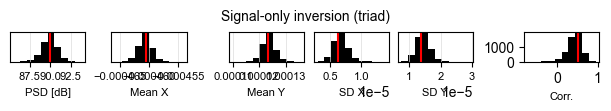

In [117]:
#__ Plot __
fig, axs = plt.subplots(
    nrows=1, ncols=6,
    figsize=(6,1), facecolor='white', layout='constrained'
)
for ax, xlims, ylims, xmajmin, ymajmin in zip(axs,
    [None, None, None, None, None],
    [None, None, None, None, None],
    [None, None, None, None, None],
    [None, None, None, None, None]
):
    if xlims: ax.set_xlim(*xlims)
    if ylims: ax.set_ylim(*ylims)
    if xmajmin:
        ax.xaxis.set_major_locator(ticker.MultipleLocator(xmajmin[0]))
        ax.xaxis.set_minor_locator(ticker.MultipleLocator(xmajmin[1]))
    if ymajmin:
        ax.yaxis.set_major_locator(ticker.MultipleLocator(ymajmin[0]))
        ax.yaxis.set_minor_locator(ticker.MultipleLocator(ymajmin[1]))
    ax.tick_params(labelsize=small)
    ax.grid(color='gainsboro', linewidth=0.5)
    ax.set_yticks([])
for ax, xlab, ylab in zip(axs,
    ["PSD [dB]", "Mean X", "Mean Y", "SD X", "SD Y", "Corr."],
    [None,None,None,None,None,None]
):
    if xlab: ax.set_xlabel(xlab, fontsize=small)
    if ylab: ax.set_ylabel(ylab, fontsize=small)
fig.suptitle("Signal-only inversion (triad)", fontsize=large)
for i, (ax, mi) in enumerate(zip(axs, m_true)):
    ax.hist(m_T[:,i], color='k', zorder=1)
    ax.axvline(mi, color='r', zorder=2)
fig.show()

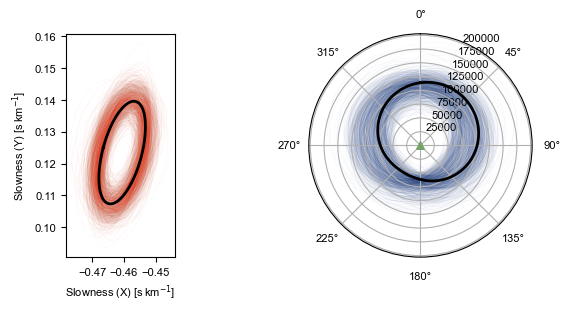

In [122]:
#________ PLOT ________#

#__ Ellipse helper __
def mahalanobis_ellipse(mean, C, q=2*np.log(2), n=400):
    """Ellipse where (s-mean)^T C^-1 (s-mean) = q."""
    vals, vecs = np.linalg.eigh(C)
    t   = np.linspace(0, 2*np.pi, n)
    pts = np.column_stack([np.cos(t), np.sin(t)]) * np.sqrt(q) * np.sqrt(vals)[None,:]
    return np.asarray(mean)[None,:] + pts @ vecs.T

def cov_from_params(sig_x, sig_y, rho):
    return np.array([[sig_x**2,        rho*sig_x*sig_y],
                     [rho*sig_x*sig_y, sig_y**2       ]])

#__ Create figure and axes __
fig = plt.figure(figsize=(6,3), facecolor='white', layout='constrained')
axs = [
    fig.add_subplot(1, 2, 1),
    fig.add_subplot(1, 2, 2, projection='polar')
]

#__ Moments of the true slowness distribution __
i_freq  = 0
w       = np.nan_to_num(energy_T[i_freq],   nan=0.0)   # (source, mode)
s       = np.nan_to_num(slowness_T[i_freq], nan=0.0)   # (source, mode, direction)
W       = w.sum()
xi_true = np.einsum('pq,pql->l', w, s) / W
ds      = s - xi_true
C_true  = np.einsum('pq,pql,pqm->lm', w, ds, ds) / W

#__ Plot signal estimates __
N_show = 1000
for j in range(N_show):
    E = mahalanobis_ellipse(m_T[j,1:3], cov_from_params(*m_T[j,3:6]))
    axs[0].plot(1e3*E[:,0], 1e3*E[:,1], c=theme[0], lw=0.3, alpha=0.05, zorder=1)

#__ Plot true signal __
E_true = mahalanobis_ellipse(xi_true, C_true)
axs[0].plot(1e3*E_true[:,0], 1e3*E_true[:,1], c='k', lw=2.0, zorder=3)

#__ Plot noise estimates __
T_dB_hat, a1_hat, b1_hat = m_J[:,0], m_J[:,1], m_J[:,2]
T_Pa_hat = 10 ** (T_dB_hat/10)
a_hat = np.column_stack([np.ones_like(a1_hat), a1_hat])
b_hat = np.column_stack([np.zeros_like(b1_hat), b1_hat])
energy_J_hat  = np.sum(e_m[None,None,:] * (a_hat[:,None,:]*cos_2D[None,:,:]
                                           + b_hat[:,None,:]*sin_2D[None,:,:]), axis=2)
energy_J_hat *= T_Pa_hat[:,None] / np.nansum(energy_J_hat, axis=1, keepdims=True)
for j in range(N_show):
    axs[1].plot(az, energy_J_hat[j], lw=0.3, alpha=0.05, color=theme[2], zorder=1)

#__ Plot true noise __
axs[1].plot(az, energy_J, lw=2.0, color='k', zorder=2)
axs[1].scatter(0, 0, marker='^', c=theme[1], s=30, zorder=3)
axs[1].set_theta_zero_location('N')
axs[1].set_theta_direction(-1)

#__ Format __
axs[0].set_aspect('equal')
axs[0].set_xlabel(r"Slowness (X) [s$\,$km$^{-1}$]", fontsize=small)
axs[0].set_ylabel(r"Slowness (Y) [s$\,$km$^{-1}$]", fontsize=small)
axs[0].tick_params(labelsize=small)
axs[1].tick_params(labelsize=small)

#__ Show figure __
fig.show()

In [ ]:
m_T.shape

(10000, 6)

(5000, 6)

(array([1021., 1000., 1056., 1012.,  984., 1004.,  971.,  975.,  989.,
         988.]),
 array([-1.99968120e-01, -1.59975308e-01, -1.19982495e-01, -7.99896828e-02,
        -3.99968702e-02, -4.05763960e-06,  3.99887549e-02,  7.99815675e-02,
         1.19974380e-01,  1.59967193e-01,  1.99960005e-01]),
 <BarContainer object of 10 artists>)

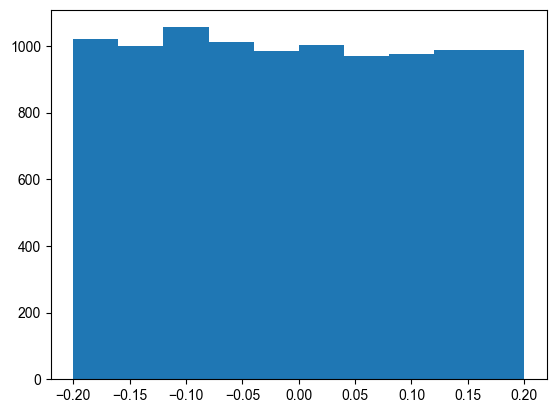

In [ ]:
plt.hist(b1_hat)

In [87]:
T_dB_hat, a1_hat, b1_hat = m_J[:,0], m_J[:,1], m_J[:,2]
T_Pa_hat = 10 ** (T_dB_hat/10)
a_hat = T_Pa_hat[:,None] * np.column_stack([np.ones_like(a1_hat), a1_hat])   # (10000, 2)
b_hat = T_Pa_hat[:,None] * np.column_stack([np.zeros_like(b1_hat), b1_hat])  # (10000, 2)
energy_J_hat = np.sum(e_m[None,None,:] * (a_hat[:,None,:]*cos_2D[None,:,:] + b_hat[:,None,:]*sin_2D[None,:,:]), axis=2)


In [85]:
cos_2D.shape

(360, 2)